<a href="https://colab.research.google.com/github/jaysulk/Poisson-GENERIC-Neural-Operators/blob/main/ICLR2027_final_integrators.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Poisson-GENERIC — the integrators asked for in the final version

Reviewer VbeA's first suggestion for the camera-ready: *"implement the Newton–Krylov solver (via matrix-free autograd JVPs) or an exponential friction step"*, because the relaxed fixed-point iteration of the discrete-gradient step does not converge and the explicit split step diverges on some long rollouts. This notebook does exactly that and nothing else.

**What it runs**

1. Trains (or loads) the four 1D FNO PG-phys models of Tables 2, 3 and 7 — same configuration, protocol and seeds.
2. **Check 1** — one frame from trained states: residual of the discrete-gradient equations after the paper's fixed-point iteration (6 / 12 / 50 iterations) against a Newton–Krylov solve.
3. **Check 2** — hundred-frame rollouts on the three input sets of Table 7 (in distribution, amplitude ×2, band $|k|\le12$) with four integrators on the *same* model:
   * `split` — the paper's integrator (exact linear step + 8 explicit sub-steps; 16 off distribution);
   * `exp` — the same splitting with the sub-steps replaced by one exponential Rosenbrock–Euler step (matrix-free $\varphi_1$);
   * `nk-dg` — the discrete-gradient step of Theorem 3, solved by Newton–Krylov, one step per frame;
   * `nk-dg/4` — the same with four steps per frame.
4. A table, LaTeX rows for an appendix table, and a figure (`fig_integrators.pdf`).

**Reading the output.** `fail`: first frame with mean relative error above 1 (or a lost sample), as in Table 7. `alive`: samples still running at the last frame (a sample is *lost* when it becomes non-finite or grows a thousand-fold). `unsolved`: samples dropped because the Newton solve failed even at the smallest step. `dE_max`: largest relative change of the model's own energy $E_\theta$ over one frame — the first law; `dS_min`: smallest change of $S$ over one frame — the second law. `n_up`: frames on which the physical energy $Q$ rises by more than 0.1 %. `s_max`: largest $|s|$ reached by the latent entropy density.

**Time.** Training: about 5 min per model on a T4, 20 min for the four. Rollouts: 44 min in a test on one CPU core with `N_TEST = 8`; the two Newton–Krylov rollouts on the amplitude-×2 wave inputs took 26 of them. The problem is 64 points in 1D, so a GPU changes this little. Checkpoints and every finished rollout are written to Drive, so a rerun resumes where it stopped. For a quick look set `N_TEST = 8` and drop the third input set.

Suggestion 2 of the review (keep the compute-matched result and the integrator limits in the main text) is a matter of the manuscript, not of code.

In [ ]:
# ===== Configuration (the only cell you may want to edit) =====
import os
SEEDS      = [0]                  # [0, 1, 2] for the final version (three seeds: three times the training and the rollouts)
PDES       = ['heat', 'advection', 'burgers', 'wave']
INPUT_SETS = ['in-distribution', 'amplitude x2', 'band |k|<=12']     # the three input sets of Table 7
T_LONG     = 100                  # rollout length in frames (the models are trained on 4-frame windows)
N_TEST     = 24                   # held-out trajectories per input set (24 = the whole test split, as in Table 7)
NK_SUBS    = [1, 4]               # discrete-gradient steps per frame: 'nk-dg' (one) and 'nk-dg/4' (four)
JVP_MODE   = 'autograd'           # Jacobian-vector products: 'autograd' (reverse-over-reverse, exact) | 'fd' (finite differences)
NK  = dict(gamma_mode='implicit', # friction coefficients at the midpoint, inside the solve (Theorem 3) | 'frozen' (App. A.5)
           tol=1e-10,             # Newton target: ||R|| <= tol ||z|| per sample
           accept=1e-8,           # a step is accepted below this; otherwise it is re-done with two half steps
           newton_max=8, gmres_m=40, eta=1e-3, min_dt=1/32)         # smallest discrete-gradient step tried, in frames
EXP = dict(n_exp=1, krylov_m=12)  # exponential step: Rosenbrock-Euler steps per frame, Krylov dimension
USE_DRIVE  = True                 # checkpoints and results go to Drive, so nothing is retrained after a disconnect
WORK = './pg_integrators'
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive'); WORK = '/content/drive/MyDrive/pg_integrators'
    except Exception as e:
        print(f'Drive not available ({type(e).__name__}); using the local folder {WORK}')
os.makedirs(f'{WORK}/ckpt', exist_ok=True)
print('work folder:', WORK)

Mounted at /content/drive
work folder: /content/drive/MyDrive/pg_integrators


## Definitions
Verbatim from `ICLR2027_poisson_generic_experiments.ipynb` (state of PR #1): configuration, solver and data, backbones, the Poisson and friction operators, the model, training and evaluation. Nothing runs in these cells.

In [ ]:
import math, time, itertools, copy, os
from dataclasses import dataclass, asdict, field
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.backends.cuda.matmul.allow_tf32 = False   # keep the structural residuals honest
torch.backends.cudnn.allow_tf32 = False
print('device:', DEV, '| torch', torch.__version__)

def seed_all(s):
    torch.manual_seed(s); np.random.seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def sdims(dim):            # spatial dims of a (B, C, *grid) tensor
    return tuple(range(-dim, 0))

def ip(a, b):              # grid-measure inner product: sum over channels and space / number of grid points -> (B,)
    # NOTE: dividing by the number of grid points only (not channels) keeps the measure independent of the channel
    # count, so Q(u) on the p observed channels and E(z) on the p+1 channels of z use the SAME inner product.  With a
    # per-channel mean, the Riesz-scaled gradient of Q came out (p+1)/p x too large (3x for the wave), the exact
    # exponential integrated only 1/(p+1) of the linear flow and the learned symbols settled at 1/2 (scalar) and 1/3 (wave).
    return (a * b).flatten(1).sum(1) / a[0, 0].numel()

def ip_pointwise(a, b):    # inner product over the channel axis only -> (B, *grid)
    return (a * b).sum(1)

def nrm(a):
    return ip(a, a).sqrt()

def neg_index(a, dim):     # a[..., k] -> a[..., (-k) mod n] on the last `dim` axes (fftn layout)
    d = sdims(dim)
    return torch.roll(torch.flip(a, d), shifts=(1,) * dim, dims=d)

device: cuda | torch 2.14.1+cu130


In [ ]:
@dataclass
class Cfg:
    # problem
    dim: int = 1
    pde: str = 'heat'            # heat | advection | burgers | wave | landau | twostream (1D-1V Vlasov-Poisson on the (x,v) grid, dim=2)
    nx: int = 64
    n_traj: int = 120
    T: int = 20                  # saved frames per trajectory (beyond t=0)
    dt: float = 0.1              # frame spacing
    kmax: int = 8                # band limit of the initial conditions
    # model
    model: str = 'pg'            # 'pg' (Poisson-GENERIC) | 'base' (unconstrained residual operator) | 'cfo' (Continuous Flow Operator baseline)
                                 #   | 'gfno' (GENERIC-FNO, this paper's protocol) | 'gfno-native' (GENERIC-FNO with its own training recipe)
    backbone: str = 'fno'        # fno | transolver | cno
    width: int = 32              # backbone width (baseline) / functional width (pg)
    modes: int = 12              # FNO modes
    layers: int = 3
    norm: bool = False           # InstanceNorm inside FNO/CNO blocks (paper: needed in 2D, harmful in 1D)
    m_L: int = 16                # band of the Poisson multiplier  (|k|_inf <= m_L, k != 0)
    m_M: int = 16                # band of the dissipative multiplier
    K_mode: str = 'complement'   # kernel band the entropy sees: 'complement' (k=0 and |k|>m_L) | 'mean' (k=0 only)
    s_init: str = 'encoder'      # latent entropy density init: 'encoder' | 'zero'
    op_init: float = 0.1         # init scale of the multiplier symbols (too small -> model starts in the identity basin)
    energy: str = 'learned'      # 'learned': E = h(mean g(u,s)) | 'physical': E = Q(u) + mean e(s), Q fixed, e >= 0 learned
    entropy: str = 'learned'     # 'learned': Casimir functional of (Pi_K u, s) | 'integral': S = mean(s) (exact Casimir)
    m_type: str = 'constant'     # 'constant': D_M multiplier | 'state': A(z)A(z)^T with A = D_M o Gamma(z), Gamma a pointwise matrix field
    n_sub: int = 1               # split integrator: sub-steps for the explicit dissipative remainder (stability: coef*k_max^2/n_sub < 2)
    flux_init: bool = True       # state-M: initialize D_M as gradient/divergence flux slots (model starts as a nonlinear diffusion)
    flux_scale: float = 0.05     # scale of that init; explicit Euler on the dissipative part is stable only if coef*k_max^2 < 2
    lie_poisson: bool = False    # scalar fields: add lambda*(u D + D u), D = sum_a d_a, to L (Lie-Poisson, Poisson; compatible with D):
                                 #   nonlinear transport (Burgers = -(1/3)(uD+Du) delta/du 1/2||u||^2) with a QUADRATIC energy
    phi_gauge: str = 'proj'    # 'taylor': subtract phi's degree-2 Taylor polynomial at 0 (removes the quadratic gauge) | 'none': phi >= 0
    conserve_mass: str = 'auto'  # 'auto': for the scalar conservation laws (heat/advection/burgers) M gets no local (zeroth-order) slot on u,
                                 #   so int u is conserved and there is no Rayleigh-type damping of a conserved density | 'yes' | 'no'
    legacy_mask: bool = False    # reproduce the SUBMITTED conserve_mass mask (local-slot column of u instead of the u row); Sec. R1 only
    dg_gamma: str = 'midpoint'   # discrete-gradient step: evaluate Gamma(z) at the 'midpoint' (as submitted) or freeze it at the
                                 #   explicit 'predictor'.  Theorem 3 holds either way (P-bar is built from the discrete gradient);
                                 #   'predictor' takes the backbone out of the fixed-point map (Reviewer VbeA Q3).
    m_coords: bool = False       # Gamma(z, x): give the friction coefficient net the grid coordinates as well as z.  Needed in phase
                                 #   space: the Dougherty drift (v - u(x)) f is a function of the coordinate v, not of f alone
    sub: int = 1                 # sub-cycling of the euler / rk4 / dg frame step (z -> z + f/sub, `sub` times).  The phase-space
                                 #   bracket is a first-order transport operator: one explicit step per frame is CFL-unstable, the
                                 #   Vlasov runs use integrator='rk4', sub=4.  Distinct from n_sub (which belongs to 'split').
    # CFO baseline (Hou, Huang & Perdikaris, ICLR 2026): flow matching on quintic-Hermite trajectory splines, RK4 at inference
    cfo_gamma0: float = 1e-5     # noise amplitude gamma_0 of the stochastic interpolant (paper: 1e-5 / 1e-6; stable up to 1e-4)
    cfo_m: int = 3               # noise-schedule exponent (C^2 schedule, matches the quintic spline)
    cfo_K: int = 4               # random (segment, tau) samples per trajectory per optimizer step (= AR horizon: same number of targets)
    cfo_substeps: int = 1        # RK4 steps per frame at inference (4 NFE each; the autoregressive models use 1 NFE per frame)
    cfo_time_cond: bool = True   # N_theta(t, u): sinusoidal embedding of the normalized time t/(T dt) appended as input channels
    # training
    epochs: int = 40
    batch: int = 16
    horizon: int = 4             # training rollout horizon
    lr: float = 1e-3
    lr_op: float = 3e-2          # learning rate of the operator symbols a(k), B(k): the true advection symbol is a(k) = -c k dt
                                 #   (= -0.8 at k=8), unreachable from a 0.1 init in ~100 Adam steps at lr 1e-3
    wd: float = 1e-4
    # evaluation
    n_roll: int = 10
    integrator: str = 'euler'    # evaluation integrator: 'euler' | 'dg' (discrete gradient, exact E/S) | 'split' (exact unitary step
                                 #   for the linear reversible part exp(L Hess Q) + Euler for the rest; physical variant only)
    train_integrator: str = 'euler'   # training integrator ('dg' is exact but ~dg_iters x slower)
    dg_iters: int = 6
    seed: int = 0

PDE_PARAMS = {
    'heat':      dict(nu=0.05),
    'advection': dict(c=1.0),
    'burgers':   dict(nu=0.02),
    'wave':      dict(c=1.0, gamma=0.3),
    # 1D-1V Vlasov-Poisson, electrons on a neutralizing ion background:  f_t + v f_x - E f_v = C[f],  E_x = 1 - rho.
    #   k0: fundamental wavenumber (box L_x = 2 pi / k0); vmax: v in [-vmax, vmax), tapered to a periodic coordinate for |v| > vc
    #   (see VlasovGrid); nu: collision frequency; alpha: range of the
    #   density-perturbation amplitude; v0: range of the beam speed (0 = Maxwellian).  collision: 'dougherty' (conservative
    #   Lenard-Bernstein, nu d_v[(v-u)f + T d_v f]: conserves mass, momentum, energy; H-theorem) | 'lb' (thermostat, NOT conservative)
    'landau':    dict(k0=0.5, vmax=4 * math.pi, vc=2 * math.pi, nu=0.04, alpha=(0.05, 0.5), v0=(0.0, 0.0), collision='dougherty'),
    'twostream': dict(k0=0.2, vmax=5 * math.pi, vc=2.5 * math.pi, nu=0.005, alpha=(0.02, 0.1), v0=(2.0, 2.5), collision='dougherty'),
    #   twostream: Dougherty relaxes towards a Maxwellian at the TOTAL temperature 1 + v0^2 ~ 7 (energy is conserved), so its
    #   diffusion coefficient nu T is large; nu = 0.005 keeps the beams (diffusion length ~0.9 over t = 16) and the instability,
    #   and the wider box (vmax = 5 pi, vc = 2.5 pi) keeps the broadened beams inside |v| < vc.  Landau: Maxwellian tails are
    #   1e-9 at 2 pi, so the narrower box (finer dv, Nyquist k_v = 8) resolves the k0 t filamentation; nu = 0.04 damps it to 0.3%
    #   by t = 12 (amplitude exp(-nu k0^2 t^3 / 3)) -- at nu = 0.02 it is still 5% at k_v = 6 and the discrete S_B is not monotone.
}
VLASOV = ('landau', 'twostream')
def is_vlasov(pde): return pde in VLASOV
def n_fields(pde):           # observed channels p
    return 2 if pde == 'wave' else 1

In [ ]:
class Spectral:
    """Spectral derivatives on the periodic box [0, 2pi)^d with integer wavenumbers."""
    def __init__(self, nx, dim, device=DEV, dtype=torch.float64):
        k = torch.fft.fftfreq(nx, d=1.0 / nx, device=device, dtype=dtype)
        self.ks = torch.meshgrid(*([k] * dim), indexing='ij')
        self.k2 = sum(kk ** 2 for kk in self.ks)
        kinf = torch.stack([kk.abs() for kk in self.ks]).amax(0)
        self.dealias_mask = (kinf < nx / 3.0)          # 2/3 rule
        self.dim = dim; self.d = sdims(dim)
    def fft(self, u):  return torch.fft.fftn(u, dim=self.d)
    def ifft(self, uh): return torch.fft.ifftn(uh, dim=self.d).real
    def deriv(self, u, axis):
        return self.ifft(1j * self.ks[axis] * self.fft(u))
    def lap(self, u):
        return self.ifft(-self.k2 * self.fft(u))
    def dealias(self, u):
        return self.ifft(self.dealias_mask * self.fft(u))

def pde_rhs(pde, u, sp, prm):
    """u: (B, p, *grid) float64. Returns du/dt."""
    if pde == 'heat':
        return prm['nu'] * sp.lap(u)
    if pde == 'advection':
        return -prm['c'] * sum(sp.deriv(u, a) for a in range(sp.dim))
    if pde == 'burgers':
        adv = sum(sp.deriv(u, a) for a in range(sp.dim))
        return -sp.dealias(u * adv) + prm['nu'] * sp.lap(u)
    if pde == 'wave':
        q, v = u[:, :1], u[:, 1:]
        return torch.cat([v, prm['c'] ** 2 * sp.lap(q) - prm['gamma'] * v], 1)
    raise ValueError(pde)

def rk4(f, u, dt):
    k1 = f(u); k2 = f(u + 0.5 * dt * k1); k3 = f(u + 0.5 * dt * k2); k4 = f(u + dt * k3)
    return u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def random_field(n, nx, dim, kmax, device=DEV, dtype=torch.float64):
    """Band-limited random field with a mild red spectrum, unit RMS."""
    sp = Spectral(nx, dim, device, dtype)
    w = torch.randn(n, 1, *([nx] * dim), device=device, dtype=dtype)
    kinf = torch.stack([kk.abs() for kk in sp.ks]).amax(0)
    mask = (kinf <= kmax) & (kinf > 0)
    amp = 1.0 / (1.0 + sp.k2) ** 0.75
    u = sp.ifft(sp.fft(w) * mask * amp)
    return u / u.flatten(1).std(1).view(n, *([1] * (dim + 1)))

def n_substeps(cfg, nx):
    """RK4 sub-steps per frame from the linear stability limit at this resolution (nu k^2 dt, c k dt < ~2.8)."""
    prm = PDE_PARAMS[cfg.pde]; kmax = nx / 2
    if cfg.pde in ('heat', 'burgers'):
        dt_max = min(0.02, 2.0 / (prm['nu'] * cfg.dim * kmax ** 2))
    else:
        dt_max = min(0.02, 2.0 / (prm['c'] * cfg.dim * kmax))
    return max(1, int(math.ceil(cfg.dt / dt_max)))

def gen_data(cfg, device=DEV):
    """Returns (n_traj, T+1, p, *grid) float32 trajectories."""
    if is_vlasov(cfg.pde): return gen_vlasov(cfg, device=device)
    seed_all(cfg.seed)
    p = n_fields(cfg.pde); prm = PDE_PARAMS[cfg.pde]
    sp = Spectral(cfg.nx, cfg.dim, device)
    u = random_field(cfg.n_traj, cfg.nx, cfg.dim, cfg.kmax, device)
    if cfg.pde == 'wave':
        v = 0.5 * random_field(cfg.n_traj, cfg.nx, cfg.dim, cfg.kmax, device)
        u = torch.cat([u, v], 1)
    n_sub = n_substeps(cfg, cfg.nx); dt_sub = cfg.dt / n_sub
    f = lambda x: pde_rhs(cfg.pde, x, sp, prm)
    frames = [u]
    with torch.no_grad():
        for _ in range(cfg.T):
            for _ in range(n_sub):
                u = rk4(f, u, dt_sub)
            frames.append(u)
    return torch.stack(frames, 1).float()

def split_data(data, frac=0.8):
    n = int(frac * data.shape[0])
    return data[:n], data[n:]

In [ ]:
def ConvNd(dim):  return {1: nn.Conv1d, 2: nn.Conv2d}[dim]
def INormNd(dim): return {1: nn.InstanceNorm1d, 2: nn.InstanceNorm2d}[dim]

def coord_grid(x):
    """(B, C, *grid) -> (B, dim, *grid) coordinates in [0,1)."""
    B, dim = x.shape[0], x.dim() - 2
    axes = [torch.linspace(0, 1, x.shape[2 + i] + 1, device=x.device, dtype=x.dtype)[:-1] for i in range(dim)]
    g = torch.stack(torch.meshgrid(*axes, indexing='ij'), 0)
    return g.unsqueeze(0).expand(B, *g.shape)

class SpectralConv(nn.Module):
    def __init__(self, dim, cin, cout, modes):
        super().__init__()
        self.dim, self.m = dim, modes
        scale = 1.0 / (cin * cout)
        shape = (cin, cout) + (modes,) * dim + (2,)
        self.w1 = nn.Parameter(scale * torch.randn(*shape))
        if dim == 2: self.w2 = nn.Parameter(scale * torch.randn(*shape))
    def forward(self, x):
        m = self.m
        if self.dim == 1:
            xf = torch.fft.rfft(x)
            out = torch.zeros(x.shape[0], self.w1.shape[1], xf.shape[-1], dtype=xf.dtype, device=x.device)
            out[:, :, :m] = torch.einsum('bim,iom->bom', xf[:, :, :m], torch.view_as_complex(self.w1))
            return torch.fft.irfft(out, n=x.shape[-1])
        xf = torch.fft.rfft2(x)
        out = torch.zeros(x.shape[0], self.w1.shape[1], *xf.shape[-2:], dtype=xf.dtype, device=x.device)
        out[:, :, :m, :m] = torch.einsum('bixy,ioxy->boxy', xf[:, :, :m, :m], torch.view_as_complex(self.w1))
        out[:, :, -m:, :m] = torch.einsum('bixy,ioxy->boxy', xf[:, :, -m:, :m], torch.view_as_complex(self.w2))
        return torch.fft.irfft2(out, s=x.shape[-2:])

class FNO(nn.Module):
    """Fourier Neural Operator (Li et al., 2021), dimension-generic, optional InstanceNorm per block."""
    def __init__(self, dim, cin, cout, width=32, modes=12, layers=3, norm=False):
        super().__init__()
        C = ConvNd(dim)
        self.lift = C(cin + dim, width, 1)
        self.specs = nn.ModuleList([SpectralConv(dim, width, width, modes) for _ in range(layers)])
        self.ws = nn.ModuleList([C(width, width, 1) for _ in range(layers)])
        self.norms = nn.ModuleList([INormNd(dim)(width, affine=True) if norm else nn.Identity() for _ in range(layers)])
        self.proj = nn.Sequential(C(width, 2 * width, 1), nn.GELU(), C(2 * width, cout, 1))
    def forward(self, x):
        x = self.lift(torch.cat([x, coord_grid(x)], 1))
        for s, w, n in zip(self.specs, self.ws, self.norms):
            x = F.gelu(n(s(x) + w(x)))
        return self.proj(x)

class PhysicsAttention(nn.Module):
    """Transolver physics-attention (Wu et al., ICML 2024): tokens -> M learned slices -> attention -> back."""
    def __init__(self, C, heads=4, slices=32):
        super().__init__()
        self.h, self.s, self.ch = heads, slices, C // heads
        self.in_proj = nn.Linear(C, C)
        self.slice_proj = nn.Linear(C, heads * slices)
        self.temp = nn.Parameter(torch.tensor(0.5))
        self.qkv = nn.Linear(self.ch, 3 * self.ch)
        self.out = nn.Linear(C, C)
    def forward(self, x):                       # x: (B, N, C)
        B, N, C = x.shape
        fx = self.in_proj(x).view(B, N, self.h, self.ch)
        w = torch.softmax(self.slice_proj(x).view(B, N, self.h, self.s) / self.temp.clamp(min=0.05), dim=-1)
        tok = torch.einsum('bnhs,bnhc->bhsc', w, fx) / (w.sum(1).unsqueeze(-1) + 1e-6)   # (B,h,S,ch)
        q, k, v = self.qkv(tok).chunk(3, -1)
        att = torch.softmax(q @ k.transpose(-1, -2) / math.sqrt(self.ch), -1)
        tok = att @ v
        y = torch.einsum('bnhs,bhsc->bnhc', w, tok).reshape(B, N, C)
        return self.out(y)

class Transolver(nn.Module):
    def __init__(self, dim, cin, cout, width=64, layers=3, heads=4, slices=32):
        super().__init__()
        self.dim = dim
        self.lift = nn.Sequential(nn.Linear(cin + dim, width), nn.GELU(), nn.Linear(width, width))
        self.blocks = nn.ModuleList()
        for _ in range(layers):
            self.blocks.append(nn.ModuleDict(dict(
                dw=ConvNd(dim)(width, width, 3, padding=1, padding_mode='circular', groups=width),   # local mixing on the grid (App. B)
                ln1=nn.LayerNorm(width), att=PhysicsAttention(width, heads, slices),
                ln2=nn.LayerNorm(width),
                mlp=nn.Sequential(nn.Linear(width, 2 * width), nn.GELU(), nn.Linear(2 * width, width)))))
        self.proj = nn.Sequential(nn.LayerNorm(width), nn.Linear(width, cout))
    def forward(self, x):
        B, C, *grid = x.shape
        t = torch.cat([x, coord_grid(x)], 1).flatten(2).transpose(1, 2)      # (B, N, C+dim)
        t = self.lift(t)
        for b in self.blocks:
            t = t + b['dw'](t.transpose(1, 2).reshape(B, -1, *grid)).flatten(2).transpose(1, 2)   # kernel-3 circular depthwise conv before each block
            t = t + b['att'](b['ln1'](t))
            t = t + b['mlp'](b['ln2'](t))
        y = self.proj(t).transpose(1, 2).reshape(B, -1, *grid)
        return y

class CNO(nn.Module):
    """CNO-style periodic convolutional operator (Raonic et al., 2023), simplified: 2-level U-shape,
    circular padding, GELU; no alias-free up/down-sampled activations (hence '-lite')."""
    def __init__(self, dim, cin, cout, width=32, layers=2, norm=False):
        super().__init__()
        C = ConvNd(dim); self.dim = dim
        def block(ci, co):
            mods = [C(ci, co, 3, padding=1, padding_mode='circular')]
            if norm: mods.append(INormNd(dim)(co, affine=True))
            mods.append(nn.GELU())
            return nn.Sequential(*mods)
        self.lift = C(cin + dim, width, 1)
        self.enc1 = nn.Sequential(*[block(width, width) for _ in range(layers)])
        self.enc2 = nn.Sequential(block(width, 2 * width), *[block(2 * width, 2 * width) for _ in range(layers - 1)])
        self.dec = nn.Sequential(block(3 * width, width), *[block(width, width) for _ in range(layers - 1)])
        self.proj = C(width, cout, 1)
        self.pool = {1: F.avg_pool1d, 2: F.avg_pool2d}[dim]
        self.mode = {1: 'linear', 2: 'bilinear'}[dim]
    def forward(self, x):
        x = self.lift(torch.cat([x, coord_grid(x)], 1))
        h1 = self.enc1(x)
        h2 = self.enc2(self.pool(h1, 2))
        up = F.interpolate(h2, size=h1.shape[2:], mode=self.mode, align_corners=False)
        return self.proj(self.dec(torch.cat([h1, up], 1)))

def make_backbone(cfg, cin, cout, width=None):
    w = width or cfg.width
    if cfg.backbone == 'fno':
        return FNO(cfg.dim, cin, cout, w, cfg.modes, cfg.layers, cfg.norm)
    if cfg.backbone == 'transolver':
        return Transolver(cfg.dim, cin, cout, max(w, 32), cfg.layers)
    if cfg.backbone == 'cno':
        return CNO(cfg.dim, cin, cout, w, max(cfg.layers - 1, 1), cfg.norm)
    raise ValueError(cfg.backbone)

def zero_last_layer(net):
    last = [m for m in net.modules() if isinstance(m, (nn.Linear, nn.Conv1d, nn.Conv2d))][-1]
    nn.init.zeros_(last.weight); nn.init.zeros_(last.bias)

def count_params(m): return sum(p.numel() for p in m.parameters())

In [ ]:
def _scatter_band(param, nx, dim):
    """param: (2m+1,)*dim tensor indexed by k in [-m..m]  ->  (nx,)*dim tensor in fftn layout."""
    m = (param.shape[-1] - 1) // 2
    assert m < nx // 2, f'band m={m} must be < nx/2={nx//2}'
    idx = torch.arange(-m, m + 1, device=param.device) % nx
    full = torch.zeros(*([nx] * dim), device=param.device, dtype=param.dtype)
    if dim == 1:
        full[idx] = param
    else:
        full[idx[:, None], idx[None, :]] = param
    return full

class PoissonOperator(nn.Module):
    """Constant-coefficient skew Fourier multiplier on the mechanical block -> Poisson (Jacobi trivially).
    Scalar field:  symbol i a(k), a odd, a=0 on the kernel band K.
    Wave (q,v):    canonical J composed with an even, non-negative multiplier d(k) (zero on K)."""
    def __init__(self, dim, p, m, K_mode='complement', canonical=False, init_scale=0.05, vlasov=False):
        super().__init__()
        self.dim, self.p, self.m, self.K_mode, self.canonical, self.vlasov = dim, p, m, K_mode, canonical, vlasov
        self.a = nn.Parameter(init_scale * torch.randn(*([2 * m + 1] * dim)))
        self.lam = nn.Parameter(torch.zeros(1))            # Lie-Poisson coefficient (scalar fields only; 0 = off)
        self.use_lp = False
        # KdV pencil: when the Lie-Poisson term is on, the constant part is restricted to alpha1 D + alpha3 D^3 (D = sum_a d_a),
        # which is COMPATIBLE with u D + D u (the bi-Hamiltonian pair of KdV), so the full L is Poisson for all parameters.
        # A generic multiplier a(k) is not compatible with the Lie-Poisson term (Jacobi fails at O(0.1)), see Sec. 7.
        self.alpha = nn.Parameter(torch.tensor([init_scale, 0.0]) if not vlasov else 0.01 * init_scale * torch.randn(2))   # Vlasov: exact value 0
        self._cache = {}
    def symbol(self, nx):
        if self.use_lp:                                    # pencil: i(alpha1 kD - alpha3 kD^3) on the band, kD = sum_a k_a
            k = torch.fft.fftfreq(nx, d=1.0 / nx, device=self.a.device)
            ks = torch.meshgrid(*([k] * self.dim), indexing='ij'); kD = sum(ks)
            kinf = torch.stack([kk.abs() for kk in ks]).amax(0); band = (kinf <= self.m) & (kinf > 0)
            # alpha3 D^3 is compatible too but its k^3 growth wrecks the discrete-gradient fixed point and the explicit
            # remainder at high k; none of the test PDEs is dispersive, so the pencil is restricted to alpha1 D + lambda(uD+Du).
            if self.vlasov:                                # phase space: {a x + b v, .} = a d_v - b d_x are the constant multipliers
                kD = self.alpha[0] * ks[1] - self.alpha[1] * ks[0]   #   compatible with the Lie-Poisson bracket (L_{f + f0}, f0 linear)
                return 1j * kD * band
            return 1j * (self.alpha[0] * kD) * band
        full = _scatter_band(self.a, nx, self.dim)
        if self.canonical:
            d2 = full ** 2
            sym = 0.5 * (d2 + neg_index(d2, self.dim))                 # even, >= 0
            sym = sym.clone(); sym[(0,) * self.dim] = 0.0              # kernel contains k=0
            return sym.to(torch.complex64 if full.dtype == torch.float32 else torch.complex128)
        odd = 0.5 * (full - neg_index(full, self.dim))                 # odd  -> real skew operator
        return 1j * odd
    def K_mask(self, nx, device):
        key = (nx, str(device))
        if key not in self._cache:
            k = torch.fft.fftfreq(nx, d=1.0 / nx, device=device)
            ks = torch.meshgrid(*([k] * self.dim), indexing='ij')
            kinf = torch.stack([kk.abs() for kk in ks]).amax(0)
            zero = (kinf == 0)
            mask = zero if self.K_mode == 'mean' else (zero | (kinf > self.m))
            self._cache[key] = mask
        return self._cache[key]
    def project_K(self, u):                      # Pi_K: orthogonal projection onto the kernel band
        d = sdims(self.dim)
        return torch.fft.ifftn(torch.fft.fftn(u, dim=d) * self.K_mask(u.shape[-1], u.device), dim=d).real
    def exp_linear(self, u, cfg, dt=1.0):
        """Exact flow of  u_t = L dQ/du  for the FIXED quadratic energy Q over time dt: a unitary per-mode map,
        exp(dt * L Hess Q).  Scalar: multiply u_hat(k) by exp(i dt a(k)) (|.|=1 -> Q conserved exactly).
        Wave (q,v), Q = 1/2(v^2 + c^2 |grad q|^2):  per-mode 2x2 exponential of [[0, d],[-d c^2 |k|^2, 0]]."""
        d = sdims(self.dim); uf = torch.fft.fftn(u, dim=d); sym = self.symbol(u.shape[-1])
        if not self.canonical:
            return torch.fft.ifftn(uf * torch.exp(dt * sym), dim=d).real
        nx = u.shape[-1]; k = torch.fft.fftfreq(nx, d=1.0 / nx, device=u.device, dtype=u.dtype)
        k2 = sum(kk ** 2 for kk in torch.meshgrid(*([k] * self.dim), indexing='ij'))
        dsym = sym.real; c2 = PDE_PARAMS['wave']['c'] ** 2
        w = dsym * (c2 * k2).sqrt()                                       # oscillation frequency per mode
        cw, sw = torch.cos(dt * w), torch.sin(dt * w)
        ratio = torch.where(w > 0, dsym / w.clamp_min(1e-30), torch.zeros_like(w))   # d/omega (q <- v coupling)
        inv = torch.where(w > 0, w / dsym.clamp_min(1e-30), torch.zeros_like(w))    # omega/d (v <- q coupling)
        q, v = uf[:, 0], uf[:, 1]
        q1 = cw * q + ratio * sw * v
        v1 = -inv * sw * q + cw * v
        return torch.fft.ifftn(torch.stack([q1, v1], 1), dim=d).real
    def phase_space_bracket(self, f, g):
        """Vlasov Lie-Poisson operator  L_f g = -{f, g}_{x,v} = -(f_x g_v - f_v g_x)  (axis -2 = x, axis -1 = v; integer grid
        wavenumbers, the box lengths are absorbed in lambda).  Discretized as the average of the two continuum-equivalent forms
           A(g) = f_x g_v - f_v g_x,     D(g) = d_v(g f_x) - d_x(g f_v),
        because  <h, D g> = -<g, A h>  holds EXACTLY on the grid (spectral derivatives are skew matrices, pointwise products
        commute), so (A + D)/2 is exactly skew-adjoint for every f -- the phase-space analogue of the uD + Du form below.
        Jacobi holds in the continuum (Lie-Poisson) and on the grid in the resolved regime (band-limited states, 3b <= nx/2),
        with the same aliasing caveat as the scalar term; verified numerically in Sec. 12.  dH/df = v~^2/2 + U gives exactly
        -v~ f_x + E f_v (v~ the periodic velocity of VlasovGrid).  Any int Phi(f) is a Casimir: -{f, Phi'(f)} = 0 pointwise."""
        d = sdims(self.dim); nx = f.shape[-1]
        k = torch.fft.fftfreq(nx, d=1.0 / nx, device=f.device, dtype=f.dtype)
        mask = (k.abs().view(nx, 1) < nx / 3.0)                   # 2/3 rule in x only (see VlasovGrid: v keeps its full spectrum)
        Dx = lambda y: torch.fft.ifft(1j * k.view(nx, 1) * torch.fft.fft(y, dim=-2), dim=-2).real
        Dv = lambda y: torch.fft.ifft(1j * k.view(1, nx) * torch.fft.fft(y, dim=-1), dim=-1).real
        P = lambda y: torch.fft.ifftn(torch.fft.fftn(y, dim=d) * mask, dim=d).real
        f = P(f); g = P(g); fx, fv = Dx(f), Dv(f)
        A = fx * Dv(g) - fv * Dx(g)
        Dd = Dv(g * fx) - Dx(g * fv)
        return -0.5 * self.lam * P(A + Dd)
    def lie_poisson(self, u, g):
        """lambda (u D g + D(u g)),  D = sum_a d_a: skew-adjoint on the grid (pointwise products are symmetric, D is skew)
        and a Hamiltonian operator (Lie-Poisson bracket of vector fields along D); the diagnostics of Sec. 7 verify Jacobi
        for the full L = constant multiplier + Lie-Poisson term numerically."""
        if self.vlasov: return self.phase_space_bracket(u, g)
        d = sdims(self.dim); nx = u.shape[-1]
        k = torch.fft.fftfreq(nx, d=1.0 / nx, device=u.device, dtype=u.dtype)
        ks = torch.meshgrid(*([k] * self.dim), indexing='ij'); Dsym = 1j * sum(ks)
        kinf = torch.stack([kk.abs() for kk in ks]).amax(0); mask = (kinf < nx / 3.0)          # 2/3-rule projector P
        D = lambda x: torch.fft.ifftn(torch.fft.fftn(x, dim=d) * Dsym, dim=d).real
        P = lambda x: torch.fft.ifftn(torch.fft.fftn(x, dim=d) * mask, dim=d).real
        # P (u D + D u) P : the sandwich keeps skewness (P symmetric) and removes quadratic aliasing.  The discrete
        # operator is Poisson only in the RESOLVED regime: Jacobi involves triple products, and holds to machine
        # precision when the fields' band b satisfies 3b <= nx/2 (see lie_poisson_jacobi_vs_resolution), but fails at
        # O(0.1) on generic full-spectrum states.  This is why the Lie-Poisson term is OFF by default: with it, exact
        # Jacobi for any state is lost, and Burgers' nonlinear transport is the price (Sec. 6 of the paper).
        u = P(u); g = P(g)
        return self.lam * P(u * D(g) + D(u * g))
    def forward(self, g, u=None):                # g: (B, p, *grid) gradient wrt u  ->  L_u g   (u needed for the LP term)
        d = sdims(self.dim); sym = self.symbol(g.shape[-1])
        mul = lambda x: torch.fft.ifftn(torch.fft.fftn(x, dim=d) * sym, dim=d).real
        if not self.canonical:
            out = mul(g)
            if self.use_lp and u is not None: out = out + self.lie_poisson(u, g)
            return out
        gq, gv = g[:, :1], g[:, 1:]
        return torch.cat([mul(gv), -mul(gq)], 1)  # J D

class DissipativeOperator(nn.Module):
    """M = (I - P_E) D_M (I - P_E), D_M a per-mode Hermitian PSD matrix symbol B(k)B(k)^H on all channels of z."""
    def __init__(self, dim, c, m, init_scale=0.05):
        super().__init__()
        self.dim, self.c, self.m = dim, c, m
        self.B = nn.Parameter(init_scale * torch.randn(c, c, *([2 * m + 1] * dim), 2))
    def symbol(self, nx):
        Bc = torch.view_as_complex(self.B)
        full = torch.stack([torch.stack([_scatter_band(Bc[i, j], nx, self.dim) for j in range(self.c)]) for i in range(self.c)])
        S = torch.einsum('ij...,kj...->ik...', full, full.conj())            # B B^H  (Hermitian PSD per mode)
        return 0.5 * (S + neg_index(S, self.dim).conj())                      # reality: S(-k) = conj S(k)
    def raw(self, v):
        d = sdims(self.dim); S = self.symbol(v.shape[-1])
        vf = torch.fft.fftn(v, dim=d)
        return torch.fft.ifftn(torch.einsum('ij...,bj...->bi...', S, vf), dim=d).real
    @staticmethod
    def proj_off(w, v, tiny=1e-30):              # (I - P_w) v   (exact ratio; guarded only against w == 0)
        coef = ip(w, v) / ip(w, w).clamp_min(tiny)
        return v - coef.view(-1, *([1] * (v.dim() - 1))) * w
    def forward(self, v, w):                     # M v, with degeneracy direction w = dE/dz
        return self.proj_off(w, self.raw(self.proj_off(w, v)))

In [ ]:
class Functional(nn.Module):
    """Scalar functional  F[z] = h( mean_x g(z) ),  g a neural operator backbone. Optional input projector."""
    def __init__(self, cfg, cin, proj=None):
        super().__init__()
        self.net = make_backbone(cfg, cin, cfg.width)
        self.head = nn.Sequential(nn.Linear(cfg.width, 64), nn.GELU(), nn.Linear(64, 1))
        self.proj = proj
    def forward(self, z, p):
        u, s = z[:, :p], z[:, p:]
        if self.proj is not None:
            u = self.proj(u)
        f = self.net(torch.cat([u, s], 1))
        return self.head(f.mean(sdims(z.dim() - 2))).squeeze(-1)

class PhysicalEnergy(nn.Module):
    """E[z] = Q(u) + mean_x phi(u) + mean_x e(s):
       Q      fixed quadratic mechanical energy (paper-1 diagnostic energy; for wave 1/2(v^2 + c^2|grad q|^2)),
       phi>=0 learned pointwise potential on u  (needed for nonlinear reversible transport: Burgers = d_x delta/du int u^3/6),
       e >=0  learned convex, increasing internal energy of the entropy density, so T = e'(s) > 0.
       E is conserved exactly and phi, e >= 0  =>  Q(u_t) <= E[z_0] for all t (bounded physical energy by construction)."""
    def __init__(self, cfg, p):
        super().__init__(); self.cfg = cfg; self.p = p
        self.phi = nn.Sequential(nn.Linear(p, 32), nn.GELU(), nn.Linear(32, 32), nn.GELU(), nn.Linear(32, 1))
        self.w_raw = nn.Parameter(-3.0 * torch.ones(16)); self.a_raw = nn.Parameter(torch.randn(16) * 0.5); self.b = nn.Parameter(torch.randn(16))
    def _quad_basis(self, x):                                            # monomials of degree <= 2 in the p channels
        cols = [torch.ones_like(x[..., 0])] + [x[..., i] for i in range(self.p)]
        cols += [x[..., i] * x[..., j] for i in range(self.p) for j in range(i, self.p)]
        return torch.stack(cols, -1)
    def potential(self, u):                                              # (B, *grid)
        """phi(u) = psi(u) - Pi_quad psi(u):  psi = softplus(MLP) >= 0, minus its weighted least-squares projection onto
        polynomials of degree <= 2, computed on a fixed Gaussian quadrature grid over the data range.  This removes the
        quadratic gauge GLOBALLY (a Taylor subtraction at u=0 does not: the network can hide a quadratic away from the
        origin, and did).  Without it phi absorbs alpha*Q, L's symbol settles at (1-alpha) x exact and the explicit
        remainder step carries the rest.  phi is not sign-definite; the bound reads Q(u_t) <= E(z_0) - |Omega| inf phi."""
        x = u.movedim(1, -1)
        psi = F.softplus(self.phi(x)).squeeze(-1)
        if getattr(self.cfg, 'phi_gauge', 'proj') == 'none':
            return psi
        if not hasattr(self, '_nodes') or self._nodes.device != u.device or self._nodes.dtype != u.dtype:
            g = torch.linspace(-4, 4, 17, device=u.device, dtype=u.dtype)
            nodes = torch.stack(torch.meshgrid(*([g] * self.p), indexing='ij'), -1).reshape(-1, self.p)
            wts = torch.exp(-0.5 * (nodes ** 2).sum(-1))                           # unit-variance Gaussian reference measure
            self._nodes, self._wts = nodes, wts
        Phi = self._quad_basis(self._nodes)                                         # (n, nb)
        psi_n = F.softplus(self.phi(self._nodes)).squeeze(-1)                       # (n,)
        W = self._wts
        A = Phi.T @ (Phi * W.unsqueeze(-1)); bvec = Phi.T @ (psi_n * W)                # weighted normal equations
        coef = torch.linalg.solve(A + 1e-8 * torch.eye(A.shape[0], device=A.device, dtype=A.dtype), bvec)
        return psi - (self._quad_basis(x) * coef).sum(-1)
    T0 = 0.1   # temperature floor: e(s) = T0 s + e_tilde(s), e_tilde convex >= 0, so T = e'(s) >= T0.  Physical friction
               # coefficients carry 1/T; without a floor, regions where s drifts negative send T -> 0 and the explicit
               # dissipative step blows up.  The energy bound survives via the second law (S non-decreasing):
               #   Q(u_t) <= E(z_0) - T0 S(z_0) - |Omega| inf phi.
    def internal(self, s):                                               # (B, *grid), convex increasing in s
        w, a = F.softplus(self.w_raw), F.softplus(self.a_raw)
        return self.T0 * s.squeeze(1) + (w * F.softplus(a * s.unsqueeze(-1) + self.b)).sum(-1).squeeze(1)
    def temperature(self, s):                                            # T = e'(s) >= T0
        w, a = F.softplus(self.w_raw), F.softplus(self.a_raw)
        return self.T0 + (w * a * torch.sigmoid(a * s.unsqueeze(-1) + self.b)).sum(-1)
    def forward(self, z, p):
        Q, _ = phys_energy(z[:, :p], self.cfg)
        return Q + self.potential(z[:, :p]).flatten(1).mean(1) + self.internal(z[:, p:]).flatten(1).mean(1)

class IntegralEntropy(nn.Module):
    """S[z] = mean_x s : the textbook Casimir. dS/dz = (0, 1) exactly."""
    def forward(self, z, p):
        return z[:, p:].flatten(1).mean(1)

class StateDissipativeOperator(DissipativeOperator):
    """M = (I-P_E) A A^T (I-P_E),  A = D_M o P(x) o Gamma(z),  with an ONSAGER PARITY structure.
    Slots (r = c*(d+1)): for each channel i, d 'flux' slots (i,a) and one 'local' slot i.
      D_M   : channel i <- flux slot (j,a) via  -i k_a * b_{ij a}(k)  (a divergence times an even real symbol),
              channel i <- local slot j  via  b'_{ij}(k) (even real symbol).  Derivative parity is fixed by construction.
      Gamma : pointwise r x r.  flux-flux and local-local blocks are arbitrary pointwise functions of z;
              flux<->local blocks are LINEAR in the gradient features (grad z)(x) with pointwise coefficients.
    Hence every path channel <- channel through M has EVEN total derivative order: M can diffuse and damp but cannot
    transport.  Without this the dissipative channel can carry advection (M(0,1)_u = -d_x(c u)), and the learned
    reversible symbol splits the transport with it (observed: exactly 1/2 of the exact a(k), 1/3 of d(k) for wave).
    The closed-form heat / damped-wave friction operators are exactly of this form (verify_representability)."""
    def __init__(self, cfg, c, m, p, init_scale=0.05, conserve_mass=False):
        nn.Module.__init__(self)
        self.dim, self.c, self.m, self.p, self.conserve_mass = cfg.dim, c, m, p, conserve_mass
        d = cfg.dim; self.d = d; self.nf = c * d; self.r = c * d + c
        # even real symbols on the band: b (c, c, d) for flux slots, b' (c, c) for local slots
        self.b = nn.Parameter(init_scale * torch.randn(c, c, d, *([2 * m + 1] * d)))
        self.bl = nn.Parameter(init_scale * torch.randn(c, c, *([2 * m + 1] * d)))
        with torch.no_grad():
            if cfg.flux_init:
                for i in range(c):
                    for a in range(d): self.b[i, i, a] += cfg.flux_scale
                    self.bl[i, i] += cfg.flux_scale
        # channel masks: no local slot into conserved-density channels (mass: the u-row of D_M has flux columns only, so
        #   (M v)_u is a divergence for every v), no friction at all on a wave's q
        rowmask = torch.ones(c); locmask = torch.ones(c)
        if cfg.pde == 'wave': rowmask[0] = 0.0
        if conserve_mass: locmask[:p] = 0.0
        self.register_buffer('row_mask', rowmask); self.register_buffer('loc_mask', locmask)
        # pointwise coefficient network on z: flux-flux block (nf x nf), local-local block (c x c),
        # cross coefficients h (nf x c x nf) and h' (c x nf x nf) multiplying gradient features
        nff, ncc, nx1, nx2 = self.nf ** 2, c ** 2, self.nf * c * self.nf, c * self.nf * self.nf
        self.m_coords = bool(getattr(cfg, 'm_coords', False))
        self.legacy_mask = bool(getattr(cfg, 'legacy_mask', False))          # Sec. R1: measure the submitted code's mass leak
        self.coef = nn.Sequential(nn.Linear(c + (d if self.m_coords else 0), 64), nn.GELU(), nn.Linear(64, 64), nn.GELU(), nn.Linear(64, nff + ncc + nx1 + nx2))
        nn.init.zeros_(self.coef[-1].weight); nn.init.zeros_(self.coef[-1].bias)
        self.gamma = None; self._cache = {}
    # ---- symbols ----
    def _even(self, prm, nx):
        full = torch.stack([_scatter_band(prm[idx], nx, self.dim) for idx in itertools.product(*[range(n) for n in prm.shape[:-self.dim]])])
        full = full.view(*prm.shape[:-self.dim], *([nx] * self.dim))
        return 0.5 * (full + neg_index(full, self.dim))
    def symbol_B(self, nx):
        """c x r complex symbol of D_M in fftn layout (columns: flux slots (j,a) then local slots j)."""
        key = (nx, str(self.b.device))
        if key not in self._cache:
            k = torch.fft.fftfreq(nx, d=1.0 / nx, device=self.b.device)
            self._cache[key] = torch.meshgrid(*([k] * self.dim), indexing='ij')
        ks = self._cache[key]
        be = self._even(self.b, nx); ble = self._even(self.bl, nx)                    # (c,c,d,*g), (c,c,*g)
        # saturated symbols: |flux symbol| < 1 and |local symbol| < 1 for ANY learned b, b'. Since M = A A^T for any A this
        # keeps symmetry/PSD/degeneracy exactly, and it bounds the gain of the dissipative operator so the explicit
        # sub-stepped remainder cannot go unstable at high k when b(k) drifts (14/72 seeds diverged without it).
        # For the physical heat symbol sqrt(nu) k the saturation is negligible on the data band ((sqrt(nu) k)^2 ~ 0.3 at k=8).
        kb = torch.stack([ks[a] * be[:, :, a] for a in range(self.d)], 2)
        flux = -1j * kb / torch.sqrt(1.0 + kb ** 2)                                     # (c, c, d, *g)
        flux = flux.reshape(self.c, self.nf, *([nx] * self.dim))
        view = (1, self.c) if self.legacy_mask else (self.c, 1)                      # legacy: the u local-slot COLUMN (submitted code)
        loc = ((ble / torch.sqrt(1.0 + ble ** 2)) * self.loc_mask.view(*view, *([1] * self.dim))).to(flux.dtype)   # BUG FIX: mask the
        #   OUTPUT row of the conserved channels (no local slot INTO u), not the u local-slot column; see Sec. 7 'mass' row
        B = torch.cat([flux, loc], 1) * self.row_mask.view(self.c, 1, *([1] * self.dim))
        return B
    # ---- state ----
    def grad_features(self, z):                                                          # (B, c*d, *grid): d_a z_j
        d = sdims(self.dim); nx = z.shape[-1]; ks = self._cache[(nx, str(z.device))] if (nx, str(z.device)) in self._cache else None
        if ks is None:
            self.symbol_B(nx); ks = self._cache[(nx, str(z.device))]
        zf = torch.fft.fftn(z, dim=d)
        g = torch.stack([torch.fft.ifftn(1j * ks[a] * zf, dim=d).real for a in range(self.d)], 2)   # (B, c, d, *g)
        return g.reshape(z.shape[0], self.nf, *z.shape[2:])
    def set_state(self, z, gE, gamma=None):
        Bsym = self.symbol_B(z.shape[-1])
        w = self._mul(gE, Bsym.conj().transpose(0, 1))
        self.w_hat = w / (ip_pointwise(w, w).sqrt().unsqueeze(1) + 1e-30)
        if gamma is not None: self.gamma = gamma; return
        B, c, nf, r = z.shape[0], self.c, self.nf, self.r
        zin = torch.cat([z, coord_grid(z)], 1) if self.m_coords else z                      # Gamma(z) or Gamma(z, x)
        co = (torch.tanh(self.coef(zin.movedim(1, -1))) / self.r).movedim(-1, 1)         # bounded so |Gamma - I| <= 1:
        # unbounded pointwise coefficients let the s-channel's local dynamics stiffen (s grew 40%/step and blew up the
        # explicit remainder step on advection); physical friction coefficients are bounded functions of the state
        i0 = 0
        ff = co[:, i0:i0 + nf * nf].view(B, nf, nf, *z.shape[2:]); i0 += nf * nf
        ll = co[:, i0:i0 + c * c].view(B, c, c, *z.shape[2:]); i0 += c * c
        h = co[:, i0:i0 + nf * c * nf].view(B, nf, c, nf, *z.shape[2:]); i0 += nf * c * nf
        hp = co[:, i0:i0 + c * nf * nf].view(B, c, nf, nf, *z.shape[2:])
        gz = self.grad_features(z)                                                       # (B, nf, *grid)
        G = torch.zeros(B, r, r, *z.shape[2:], device=z.device, dtype=z.dtype)
        eye_f = torch.eye(nf, device=z.device, dtype=z.dtype).view(1, nf, nf, *([1] * self.dim))
        eye_l = torch.eye(c, device=z.device, dtype=z.dtype).view(1, c, c, *([1] * self.dim))
        G[:, :nf, :nf] = eye_f + ff
        G[:, nf:, nf:] = eye_l + ll
        G[:, :nf, nf:] = torch.einsum('bijk...,bk...->bij...', h, gz)                    # flux <- local: linear in grad z
        G[:, nf:, :nf] = torch.einsum('bijk...,bk...->bij...', hp, gz)                   # local <- flux: linear in grad z
        self.gamma = G
    def _mul(self, v, Bsym):
        d = sdims(self.dim); vf = torch.fft.fftn(v, dim=d)
        return torch.fft.ifftn(torch.einsum('ij...,bj...->bi...', Bsym, vf), dim=d).real
    def _P(self, w):
        return w - ip_pointwise(self.w_hat, w).unsqueeze(1) * self.w_hat
    def raw(self, v):                           # A A^T v = D_M P Gamma Gamma^T P D_M^H v
        Bsym = self.symbol_B(v.shape[-1])
        w = self._P(self._mul(v, Bsym.conj().transpose(0, 1)))
        w = torch.einsum('bji...,bj...->bi...', self.gamma, w)
        w = torch.einsum('bij...,bj...->bi...', self.gamma, w)
        return self._mul(self._P(w), Bsym)
    def forward(self, v, w, project=False):
        if not project: return self.raw(v)
        return self.proj_off(w, self.raw(self.proj_off(w, v)))

class PoissonGENERIC(nn.Module):
    """dz/dt = L dE/dz + M dS/dz  on z = (u, s):  L constant Poisson, S a Casimir of L by construction,
    M PSD with the projection sandwich.  Full metriplectic structure, exact for any parameters."""
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg; self.p = n_fields(cfg.pde); c = self.p + 1
        self.L = PoissonOperator(cfg.dim, self.p, cfg.m_L, cfg.K_mode, canonical=(cfg.pde == 'wave'), init_scale=cfg.op_init,
                                 vlasov=is_vlasov(cfg.pde))
        self.L.use_lp = bool(getattr(cfg, 'lie_poisson', False)) and cfg.pde != 'wave' and cfg.energy == 'physical'
        cm = (cfg.pde != 'wave') if cfg.conserve_mass == 'auto' else (cfg.conserve_mass == 'yes')   # scalar conservation laws conserve int u
        self.M = (StateDissipativeOperator(cfg, c, cfg.m_M, self.p, init_scale=cfg.op_init, conserve_mass=cm) if cfg.m_type == 'state'
                  else DissipativeOperator(cfg.dim, c, cfg.m_M, init_scale=cfg.op_init))
        self.E = PhysicalEnergy(cfg, self.p) if cfg.energy == 'physical' else Functional(cfg, c)
        self.S = IntegralEntropy() if cfg.entropy == 'integral' else Functional(cfg, c, proj=self.L.project_K)
        self.enc = make_backbone(cfg, self.p, 1, width=max(cfg.width // 2, 8)) if cfg.s_init == 'encoder' else None
    # ---- state ----
    def init_state(self, u):
        s = self.enc(u) if self.enc is not None else torch.zeros_like(u[:, :1])
        return torch.cat([u, s], 1)
    def Lz(self, g, z=None):                     # L acts on the u-block only; s-block of L is zero
        u = z[:, :self.p] if z is not None else None
        return torch.cat([self.L(g[:, :self.p], u), torch.zeros_like(g[:, self.p:])], 1)
    def Lz_const(self, g):                       # constant-multiplier part of L only (no Lie-Poisson term)
        return torch.cat([self.L(g[:, :self.p], None), torch.zeros_like(g[:, self.p:])], 1)
    def PiK_z(self, d):                          # projection onto ker L  (K modes of u, all of s)
        return torch.cat([self.L.project_K(d[:, :self.p]), d[:, self.p:]], 1)
    def grads(self, z, create_graph=True):
        with torch.enable_grad():
            if not z.requires_grad: z = z.requires_grad_(True)
            E = self.E(z, self.p); S = self.S(z, self.p)
            N = z[0, 0].numel()   # Riesz representative w.r.t. the grid-measure inner product: (#grid points) x the autodiff gradient
            gE = N * torch.autograd.grad(E.sum(), z, create_graph=create_graph)[0]
            gS = N * torch.autograd.grad(S.sum(), z, create_graph=create_graph)[0]
        return E, S, gE, gS
    def vector_field(self, z, create_graph=True):
        E, S, gE, gS = self.grads(z, create_graph)
        if isinstance(self.M, StateDissipativeOperator): self.M.set_state(z, gE)
        f = self.Lz(gE, z) + self.M(gS, gE)
        return f, dict(E=E, S=S, gE=gE, gS=gS)
    # ---- integrators ----
    def step_euler(self, z, create_graph=True, scale=1.0):
        f, aux = self.vector_field(z, create_graph)
        return z + scale * f, aux
    def step_rk4(self, z, create_graph=True, scale=1.0):
        """Classical RK4 on the learned metriplectic vector field (the frame map is exp(scale * f)).  Not exactly conservative
        (O(scale^5) per step) but stable for first-order transport operators such as the phase-space bracket at CFL < 2.8;
        the DG step gives the exact laws.  aux is from the frame's start state."""
        k1, aux = self.vector_field(z, create_graph); k2, _ = self.vector_field(z + 0.5 * scale * k1, create_graph)
        k3, _ = self.vector_field(z + 0.5 * scale * k2, create_graph); k4, _ = self.vector_field(z + scale * k3, create_graph)
        return z + scale / 6 * (k1 + 2 * k2 + 2 * k3 + k4), aux
    def step_dg(self, z, iters=None, create_graph=False, scale=1.0):
        """Discrete-gradient (Gonzalez) step. dE/dz uses the standard correction; dS/dz uses the correction
        restricted to ker L, so L gS_bar = 0 still holds and both laws are exact in discrete time (Thm 2)."""
        iters = iters or self.cfg.dg_iters
        z1, aux = self.step_euler(z, create_graph, scale)
        E0 = aux['E']; S0 = aux['S']
        gam = None
        if isinstance(self.M, StateDissipativeOperator) and getattr(self.cfg, 'dg_gamma', 'midpoint') == 'predictor':
            self.M.set_state(z1, aux['gE']); gam = self.M.gamma               # Gamma frozen at the predictor; P-bar still from gE-bar below
        for it in range(iters):
            zm = 0.5 * (z + z1); d = z1 - z
            E1, S1 = self.E(z1, self.p), self.S(z1, self.p)
            _, _, gE, gS = self.grads(zm, create_graph)
            if isinstance(self.M, StateDissipativeOperator): self.M.set_state(zm, gEb if it > 0 else gE, gamma=gam)
            cE = (E1 - E0 - ip(gE, d)) / (ip(d, d) + 1e-30)
            gEb = gE + cE.view(-1, *([1] * (z.dim() - 1))) * d
            dK = self.PiK_z(d)
            cS = (S1 - S0 - ip(gS, d)) / (ip(dK, dK) + 1e-30)
            gSb = gS + cS.view(-1, *([1] * (z.dim() - 1))) * dK
            z_new = z + scale * (self.Lz(gEb, zm) + self.M(gSb, gEb))
            z1 = z_new if it == iters - 1 else 0.5 * (z1 + z_new)     # relaxed iterations, plain final update
        aux.update(dict(gEbar=gEb, gSbar=gSb))
        return z1, aux
    def step_split(self, z, create_graph=True):
        """Strang split: exact unitary half-step of the linear reversible flow (conserves Q exactly), Euler step of the
        remainder (nonlinear potential + dissipation), exact half-step again.  Physical-energy variant only."""
        assert isinstance(self.E, PhysicalEnergy), 'split integrator needs the fixed quadratic energy'
        assert not is_vlasov(self.cfg.pde), 'split integrator needs Q = 1/2||u||^2 (exp_linear); use rk4 or dg with sub-cycling for Vlasov'
        p = self.p
        u = self.L.exp_linear(z[:, :p], self.cfg, 0.5); z = torch.cat([u, z[:, p:]], 1)
        f, aux = self.vector_field(z, create_graph)
        _, gQ = phys_energy(z[:, :p], self.cfg)                            # linear part of dE/du, already integrated exactly
        f = f - self.Lz_const(torch.cat([gQ, torch.zeros_like(z[:, p:])], 1))   # subtract ONLY the constant-multiplier part
        z = z + f / self.cfg.n_sub
        for _ in range(self.cfg.n_sub - 1):                                # optional sub-cycling of the stiff dissipative remainder
            f, _ = self.vector_field(z, create_graph); _, gQ = phys_energy(z[:, :p], self.cfg)
            z = z + (f - self.Lz_const(torch.cat([gQ, torch.zeros_like(z[:, p:])], 1))) / self.cfg.n_sub
        u = self.L.exp_linear(z[:, :p], self.cfg, 0.5); z = torch.cat([u, z[:, p:]], 1)
        return z, aux
    def step(self, z, create_graph=True, integrator=None):
        integrator = integrator or self.cfg.integrator
        if integrator == 'split':
            return self.step_split(z, create_graph)
        n = max(1, int(getattr(self.cfg, 'sub', 1))); aux0 = None
        for _ in range(n):                                   # sub-cycling (sub = 1 reproduces the original single step)
            if integrator == 'dg':    z, aux = self.step_dg(z, create_graph=create_graph, scale=1.0 / n)
            elif integrator == 'rk4': z, aux = self.step_rk4(z, create_graph, scale=1.0 / n)
            else:                     z, aux = self.step_euler(z, create_graph, scale=1.0 / n)
            if aux0 is None: aux0 = aux
        return z, aux0
    def rollout(self, u0, n, create_graph=True, keep_aux=False, integrator=None):
        z = self.init_state(u0); us, zs, auxs = [], [z], []
        for _ in range(n):
            z, aux = self.step(z, create_graph, integrator)
            if not create_graph: z = z.detach()
            us.append(z[:, :self.p]); zs.append(z)
            if keep_aux: auxs.append({k: v.detach() for k, v in aux.items()})
        return torch.stack(us, 1), torch.stack(zs, 1), auxs

class Baseline(nn.Module):
    """Unconstrained residual operator  u_{t+1} = u_t + G(u_t)."""
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg; self.p = n_fields(cfg.pde)
        self.net = make_backbone(cfg, self.p, self.p)
    def rollout(self, u0, n, create_graph=True, keep_aux=False, integrator=None):
        u = u0; us = []
        for _ in range(n):
            u = u + self.net(u); us.append(u)
        return torch.stack(us, 1), None, []

def make_model(cfg):
    return {'pg': PoissonGENERIC, 'base': Baseline, 'cfo': CFO, 'gfno': GENERICFNO, 'gfno-native': GENERICFNO}[cfg.model](cfg).to(DEV)

In [ ]:
def phys_energy(u, cfg):
    """Fixed quadratic physical energy Q(u) and its gradient dQ/du (no learned quantity involved)."""
    if is_vlasov(cfg.pde):                                   # Vlasov-Poisson Hamiltonian (linear + quadratic in f), gradient v^2/2 + U
        return vgrid(cfg.pde, u.shape[-1], u.device, u.dtype).hamiltonian(u)
    if cfg.pde != 'wave':
        return 0.5 * ip(u, u), u
    sp = Spectral(u.shape[-1], cfg.dim, u.device, u.dtype); c2 = PDE_PARAMS['wave']['c'] ** 2
    q, v = u[:, :1], u[:, 1:]
    Q = 0.5 * (ip(v, v) - c2 * ip(q, sp.lap(q)))
    return Q, torch.cat([-c2 * sp.lap(q), v], 1)

def rel_l2(pred, true):                          # per-sample relative L2, averaged -> scalar
    return (nrm(pred - true) / (nrm(true) + 1e-12)).mean()

def train_model(model, data, cfg, verbose=True):
    if cfg.model == 'gfno-native': return train_gfno_native(model, data, cfg, verbose)   # GENERIC-FNO's own recipe (Sec. R3)
    op_names = {'L.a', 'L.lam', 'L.alpha', 'M.b', 'M.bl'}   # operator symbols get the large lr; the friction symbols are saturated (|.|<1), so this is safe
    op_params = [p for n, p in model.named_parameters() if n in op_names]
    other = [p for n, p in model.named_parameters() if n not in op_names]
    groups = [dict(params=other, lr=cfg.lr)] + ([dict(params=op_params, lr=cfg.lr_op, weight_decay=0.0)] if op_params else [])
    opt = torch.optim.AdamW(groups, lr=cfg.lr, weight_decay=cfg.wd)
    n_iter = cfg.epochs * math.ceil(data.shape[0] / cfg.batch)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g['lr'] for g in groups], total_steps=n_iter, pct_start=0.1)
    H = cfg.horizon; model.train(); t0 = time.time(); hist = []
    for ep in range(cfg.epochs):
        perm = torch.randperm(data.shape[0]); tot = 0.0; nb = 0
        for i in range(0, data.shape[0], cfg.batch):
            traj = data[perm[i:i + cfg.batch]].to(DEV)
            if isinstance(model, CFO):                       # flow matching on the whole trajectory (no rollout in training)
                loss = model.fm_loss(traj)
            else:
                t_start = np.random.randint(0, cfg.T - H + 1)
                u0 = traj[:, t_start]; target = traj[:, t_start + 1:t_start + 1 + H]
                pred, _, _ = model.rollout(u0, H, create_graph=True, integrator=cfg.train_integrator)
                loss = sum(rel_l2(pred[:, h], target[:, h]) for h in range(H)) / H
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); tot += loss.item(); nb += 1
        hist.append(tot / nb)
        if verbose and (ep % max(1, cfg.epochs // 5) == 0 or ep == cfg.epochs - 1):
            print(f'  ep {ep:3d}  loss {tot/nb:.4f}  ({time.time()-t0:.0f}s)')
    return hist

@torch.no_grad()
def evaluate(model, data, cfg):
    """Rollout from t=0 for cfg.n_roll steps on held-out trajectories. Returns accuracy + structural diagnostics."""
    model.eval(); out = {}
    traj = data.to(DEV); n = min(cfg.n_roll, cfg.T)
    u0 = traj[:, 0]; true = traj[:, 1:1 + n]
    pred, zs, auxs = model.rollout(u0, n, create_graph=False, keep_aux=True)
    errs = [rel_l2(pred[:, t], true[:, t]).item() for t in range(n)]
    out['l2_1step'] = errs[0]; out['l2_rollout'] = float(np.mean(errs)); out['l2_final'] = errs[-1]
    # gauge-invariant dissipation of the FIXED physical energy Q (references no learned quantity):
    #   scalar PDEs: Q = 1/2||u||^2 ;  wave: Q = 1/2(||v||^2 + c^2||grad q||^2)   (Q of the observed field alone
    #   is not an invariant of the wave, cf. GENERIC-FNO Sec. 5.4).  r_mech = -<dQ/du, du> / (||dQ/du|| ||du||).
    prev = torch.cat([u0[:, None], pred[:, :-1]], 1).flatten(0, 1); du = (pred - prev.view_as(pred)).flatten(0, 1)
    # midpoint form: for a quadratic Q, -<dQ/du(u_mid), du> = Q(u) - Q(u') exactly, so an exactly Q-conserving step
    # (e.g. transport) gives r_mech = 0; the endpoint form has an O(|du|/|u|) bias (~0.1 at this frame spacing)
    _, gQ = phys_energy(0.5 * (prev + prev + du), cfg)
    out['rmech'] = (-ip(gQ, du) / (nrm(gQ) * nrm(du) + 1e-12)).mean().item()
    tprev = torch.cat([u0[:, None], true[:, :-1]], 1).flatten(0, 1)
    Qt0, _ = phys_energy(tprev, cfg); Qt1, _ = phys_energy(true.flatten(0, 1), cfg)
    out['Pi_star'] = ((Qt0 - Qt1) / (Qt0 + 1e-12)).mean().item()
    # same normalization as Pi_star (fractional one-step change of the fixed Q), so model and truth compare by MAGNITUDE,
    # not only by rank: r_mech is a cosine and under-weights dissipation on transport-dominated flows (Burgers)
    Qm0, _ = phys_energy(prev, cfg); Qm1, _ = phys_energy(pred.flatten(0, 1), cfg)
    out['Pi_model'] = ((Qm0 - Qm1) / (Qm0 + 1e-12)).mean().item()
    out['Q_ratio_final'] = (phys_energy(pred[:, -1], cfg)[0] / phys_energy(true[:, -1], cfg)[0]).mean().item()
    if pred.shape[2] == 1:                                   # scalar conservation laws: drift of int u along the rollout, relative to ||u0||
        m0 = u0.flatten(1).mean(1, keepdim=True); mt = pred[:, :, 0].flatten(2).mean(2)
        out['mass_drift'] = ((mt - m0).abs().amax(1) / (nrm(u0) + 1e-12)).mean().item()
        mtrue = true[:, :, 0].flatten(2).mean(2); out['mass_drift_true'] = ((mtrue - m0).abs().amax(1) / (nrm(u0) + 1e-12)).mean().item()
    if isinstance(model, GENERICFNO): out.update(model.diagnostics(u0, pred))
    if is_vlasov(cfg.pde): out.update(vlasov_metrics(pred, true, u0, cfg))
    if isinstance(model, CFO): out['nfe_per_frame'] = 4 * cfg.cfo_substeps
    if isinstance(model, PoissonGENERIC):
        if isinstance(model.E, PhysicalEnergy):    # Theorem: Q(u_t) <= E[z_0] - |Omega| inf phi   (= E[z_0] when phi >= 0)
            E0 = model.E(zs[:, 0], model.p)
            Qmax = torch.stack([phys_energy(pred[:, t], cfg)[0] for t in range(n)], 1).amax(1)
            phi_min = torch.stack([model.E.potential(pred[:, t]).flatten(1).amin(1) for t in range(n)], 1).amin(1).clamp(max=0)
            S0 = zs[:, 0, model.p:].flatten(1).mean(1)
            out['phi_min'] = phi_min.min().item()
            out['Qmax_over_E0'] = (Qmax / E0).max().item()
            out['Qmax_over_bound'] = (Qmax / (E0 - model.E.T0 * S0 - phi_min)).max().item()      # theorem: <= 1
        rE, dE, dS, sgn = [], [], [], []
        for t, aux in enumerate(auxs):
            dz = zs[:, t + 1] - zs[:, t]; g = aux.get('gEbar', aux['gE'])   # DG: test against the discrete gradient
            rE.append((ip(g, dz).abs() / (nrm(g) * nrm(dz) + 1e-30)).mean().item())
            E1, S1, _, _ = model.grads(zs[:, t + 1], create_graph=False)
            dE.append(((E1 - aux['E']).abs() / (aux['E'].abs() + 1e-12)).mean().item())
            dS.append((S1 - aux['S']).min().item())
        out['rE'] = float(np.mean(rE)); out['dE_rel'] = float(np.mean(dE)); out['min_dS'] = float(np.min(dS))
    return out

In [ ]:
# Model classes this notebook never builds; the stubs keep the isinstance checks inside train_model / evaluate valid.
class CFO(nn.Module): pass
class GENERICFNO(nn.Module): pass

_DATA_CACHE = {}
def get_data(cfg):
    key = (cfg.dim, cfg.pde, cfg.nx, cfg.n_traj, cfg.T, cfg.dt, cfg.kmax, cfg.seed)
    if key not in _DATA_CACHE:
        _DATA_CACHE[key] = gen_data(cfg).cpu()
    return _DATA_CACHE[key]

def run_one(cfg, verbose=True):
    seed_all(cfg.seed + 1)
    data = get_data(cfg); tr, te = split_data(data)
    model = make_model(cfg)
    if verbose: print(f'[{cfg.dim}D {cfg.pde:9s} {cfg.backbone:10s} {cfg.model:4s}] params={count_params(model):,}')
    t0 = time.time(); hist = train_model(model, tr, cfg, verbose)
    row = dict(dim=cfg.dim, pde=cfg.pde, backbone=cfg.backbone, model=cfg.model, seed=cfg.seed,
               params=count_params(model), train_s=time.time() - t0, final_loss=hist[-1])
    row.update(evaluate(model, te, cfg))
    # persistence reference
    te_d = te.to(DEV); n = min(cfg.n_roll, cfg.T)
    row['l2_persist'] = float(np.mean([rel_l2(te_d[:, 0], te_d[:, 1 + t]).item() for t in range(n)]))
    if verbose: print('   ', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items() if k not in ('dim','pde','backbone','model','seed')})
    return row, model

## 1. The trained models
Loaded from `ckpt/` if present, trained otherwise (paper protocol: 60 epochs, 4-frame rollout loss, split integrator with 8 sub-steps). `gauge_a` is the curvature of the quadratic removed from the learned potential; $a<\tfrac12$ is the coercivity hypothesis of Theorem 2.

In [ ]:
# ===== The trained models: 1D FNO PG-phys, the configuration of Tables 2, 3 and 7 =====
import json
PG_PHYS = dict(model='pg', energy='physical', entropy='integral', m_type='state', integrator='split', train_integrator='split', n_sub=8, lie_poisson=True)
def cfg_pg(pde, seed):
    c = Cfg(dim=1, pde=pde, nx=64, n_traj=120, T=20, kmax=8, m_L=16, m_M=16, width=24, modes=12, layers=3, epochs=60, batch=16, horizon=4, norm=False)
    for k, v in PG_PHYS.items(): setattr(c, k, v)
    c.m_M = c.nx // 3; c.backbone, c.seed = 'fno', seed
    return c

MODELS = {}
def get_model(pde, seed):
    """Trained float32 model: from memory, else from its checkpoint, else trained now with the paper's protocol (and saved)."""
    key = (pde, seed); path = f'{WORK}/ckpt/1D_{pde}_pgphys_{seed}.pt'
    if key in MODELS: return MODELS[key]
    c = cfg_pg(pde, seed)
    if os.path.exists(path):
        m = make_model(c); m.load_state_dict(torch.load(path, map_location=DEV))
    else:
        get_data(c)                                   # data first: the model is then initialized from the same RNG state as in the paper's runs
        t0 = time.time(); row, m = run_one(c, verbose=False); torch.save(m.state_dict(), path)
        print(f'  trained 1D {pde} seed {seed}: {time.time() - t0:.0f}s, ten-frame error {row["l2_rollout"]:.4f}')
    MODELS[key] = m.eval(); return MODELS[key]

def gauge_curvature(m):
    """a = lambda_max(A), A the quadratic part removed from the potential (phi >= -(u^T A u + b.u + c0)).  For the scalar
    equations a < 1/2 is the coercivity hypothesis of Theorem 2: the energy then bounds Q at every amplitude."""
    Eo, p = m.E, m.p; prm = next(Eo.phi.parameters())
    g = torch.linspace(-4, 4, 17, device=prm.device, dtype=prm.dtype)
    nodes = torch.stack(torch.meshgrid(*([g] * p), indexing='ij'), -1).reshape(-1, p); W = torch.exp(-0.5 * (nodes ** 2).sum(-1))
    with torch.no_grad():
        Phi = Eo._quad_basis(nodes); psi = F.softplus(Eo.phi(nodes)).squeeze(-1)
        A_ = Phi.T @ (Phi * W.unsqueeze(-1)); coef = torch.linalg.solve(A_ + 1e-8 * torch.eye(A_.shape[0], device=A_.device, dtype=A_.dtype), Phi.T @ (psi * W))
    A = torch.zeros(p, p, dtype=prm.dtype); i0 = 1 + p
    for i in range(p):
        for j in range(i, p):
            A[i, j] += coef[i0].item() / (1 if i == j else 2); A[j, i] = A[i, j]; i0 += 1
    return torch.linalg.eigvalsh(A).max().item()

PAPER = dict(heat=0.0161, advection=0.0011, burgers=0.033, wave=0.028)     # Table 2, 1D FNO PG-phys, three-seed means
rows_m = []
for seed in SEEDS:
    for pde in PDES:
        m = get_model(pde, seed); c = cfg_pg(pde, seed); _, te = split_data(get_data(c)); r = evaluate(m, te, c)
        rows_m.append(dict(pde=pde, seed=seed, l2_rollout=r['l2_rollout'], paper_mean=PAPER[pde], Q10_over_truth=r['Q_ratio_final'],
                           dE_split=r['dE_rel'], gauge_a=gauge_curvature(m), params=count_params(m)))
df_models = pd.DataFrame(rows_m)
with pd.option_context('display.float_format', lambda x: f'{x:.3g}'): display(df_models.set_index(['pde', 'seed']))
# l2_rollout should sit near paper_mean (same protocol and seeds; GPU round-off changes the third digit).  dE_split is the
# relative change of the model's own energy per frame under the split step: not zero, which is what the solvers below remove.

  trained 1D heat seed 0: 333s, ten-frame error 0.0135
  trained 1D advection seed 0: 318s, ten-frame error 0.0017
  trained 1D burgers seed 0: 320s, ten-frame error 0.0324
  trained 1D wave seed 0: 411s, ten-frame error 0.0273


,,l2_rollout,paper_mean,Q10_over_truth,dE_split,gauge_a,params
pde,seed,,,,,,
heat,0,0.0135,0.0161,1.02,2.91e-05,-0.017,18702
advection,0,0.00173,0.0011,0.999,7.93e-08,0.00385,18702
burgers,0,0.0324,0.033,1,0.000582,-0.000461,18702
wave,0,0.0273,0.028,1.06,0.000122,-0.000967,22360


## 2. The integrators
* `step_nk_dg` solves the discrete-gradient equations $R(z_1)=z_1-z-\Delta t\,[L(\bar z)\,\overline{\nabla}E+M(\bar z)\,\overline{\nabla}S]=0$ per sample: inexact Newton, GMRES on Jacobian–vector products (reverse-over-reverse automatic differentiation: one graph per Newton iteration, one backward pass per product; no Jacobian is formed), backtracking on $\|R\|$. At $R=0$ both discrete laws are exact for any step size.
* `dg_advance` re-does a step that did not converge with two half steps (recursively, down to `min_dt`).
* `step_exp` keeps the paper's Strang splitting and replaces the explicit sub-steps of the remainder by $z\leftarrow z+h\,\varphi_1(hJ)\,r(z)$ from a Krylov space.

All solves run in double precision on a float64 copy of the trained weights.

In [ ]:
# ---- helpers -------------------------------------------------------------------------------------------------------------
def _bc(v, like):                                   # (B,) -> broadcastable against like
    return v.view(-1, *([1] * (like.dim() - 1)))
def _safe_div(num, den, tiny=1e-24):                # 0 where the denominator vanishes (d = 0: the correction is not needed)
    return torch.where(den > tiny, num / den.clamp_min(tiny), torch.zeros_like(num))
def _fnorm(x):                                      # per-sample Euclidean norm of a (B, ...) tensor
    return x.flatten(1).norm(dim=1)

def to_double(mdl32, cfg):
    """Float64 copy of a trained model (same weights).  The solvers below run in double precision: the laws are then
    testable down to the solve tolerance instead of the float32 round-off (~1e-7)."""
    m = make_model(copy.deepcopy(cfg)).double()
    m.load_state_dict({k: (v.double() if v.is_floating_point() else v) for k, v in mdl32.state_dict().items()})
    return m.eval()

# ---- Jacobian-vector products, matrix-free ---------------------------------------------------------------------------------
class JVP:
    """J v for a batched map fun: (B, ...) -> (B, ...) acting sample-wise, at the point x.
    mode='autograd': reverse-over-reverse.  One graph of  g(u) = J^T u  is built at x; every product J v is then a single
                     backward pass through it (no new evaluation of fun).  Exact to round-off.
    mode='fd'      : forward differences of fun in float64 (one evaluation per product); kept as an independent check."""
    def __init__(self, fun, x, mode='autograd', Fx=None):
        self.mode, self.shape = mode, x.shape
        if mode == 'autograd':
            self.x = x.detach().requires_grad_(True)
            with torch.enable_grad():
                y = fun(self.x, True)
                self.u = torch.zeros_like(y, requires_grad=True)
                self.g, = torch.autograd.grad(y, self.x, self.u, create_graph=True)
        else:
            self.fun, self.x = fun, x.detach()
            with torch.no_grad(): self.Fx = fun(self.x, False).detach() if Fx is None else Fx
            self.xn = 1.0 + _fnorm(self.x)
    def __call__(self, v):                          # v: (B, N) flattened -> (B, N)
        v = v.view(self.shape)
        if self.mode == 'autograd':
            return torch.autograd.grad(self.g, self.u, v, retain_graph=True)[0].flatten(1)
        vn = _fnorm(v).clamp_min(1e-300); eps = 1e-7 * self.xn / vn
        with torch.no_grad(): Fp = self.fun(self.x + _bc(eps, v) * v, False)
        return ((Fp - self.Fx) / _bc(eps, v)).flatten(1)

# ---- batched Krylov: every sample is its own linear system -----------------------------------------------------------------
def arnoldi(Av, b, m, tol=None):
    """Per-sample Arnoldi (modified Gram-Schmidt) on K_m(J, b).  b: (B, N).  Returns V (list of (B, N)), H (B, m+1, m),
    beta (B,), the number of Krylov vectors used and, if tol is given, the GMRES solution of J x = b with x0 = 0 (stops as
    soon as every sample's relative residual is below tol)."""
    B = b.shape[0]; beta = b.norm(dim=1); bs = beta.clamp_min(1e-300)
    V = [b / bs[:, None]]; H = torch.zeros(B, m + 1, m, dtype=b.dtype, device=b.device)
    y, rel, k_used = None, torch.ones(B, dtype=b.dtype), 0
    for k in range(m):
        w = Av(V[k])
        for j in range(k + 1):
            h = (w * V[j]).sum(1); H[:, j, k] = h; w = w - h[:, None] * V[j]
        hn = w.norm(dim=1); H[:, k + 1, k] = hn
        V.append(torch.where((hn > 1e-13 * (1.0 + H[:, :k + 1, k].norm(dim=1)))[:, None], w / hn.clamp_min(1e-300)[:, None], torch.zeros_like(w)))
        k_used = k + 1
        if tol is not None:
            Hk = torch.nan_to_num(H[:, :k + 2, :k + 1].cpu(), nan=0.0, posinf=0.0, neginf=0.0)
            e1 = torch.zeros(B, k + 2, 1, dtype=b.dtype); e1[:, 0, 0] = torch.nan_to_num(beta.cpu(), nan=0.0, posinf=0.0, neginf=0.0)
            y = torch.linalg.lstsq(Hk, e1, driver='gelsd').solution
            rel = (Hk @ y - e1).squeeze(-1).norm(dim=1) / bs.cpu()
            if rel.max() < tol: break
    x = None
    if tol is not None:
        y = y.squeeze(-1).to(b.device); x = sum(y[:, j, None] * V[j] for j in range(k_used))
    return V, H, beta, k_used, x, rel

def phi1_krylov(Av, r, h, m):
    """h * phi_1(h J) r,  phi_1(x) = (e^x - 1)/x, per sample, from an m-dimensional Krylov space:
    exp([[hH, h beta e1], [0, 0]]) carries h phi_1(hH) beta e1 in its last column."""
    V, H, beta, k, _, _ = arnoldi(Av, r, m)
    B = r.shape[0]; aug = torch.zeros(B, k + 1, k + 1, dtype=r.dtype, device=r.device)
    aug[:, :k, :k] = h * H[:, :k, :k]; aug[:, 0, k] = h * beta
    coef = torch.linalg.matrix_exp(aug)[:, :k, k]
    return sum(coef[:, j, None] * V[j] for j in range(k))

# ---- (A) discrete-gradient step solved by Newton-Krylov ----------------------------------------------------------------------
def dg_residual(mdl, z, z1, dt, E0, S0, gamma=None, graph=False):
    """R(z1) = z1 - z - dt [ L(zm) gE_bar + M(zm; gE_bar) gS_bar ],  zm = (z + z1)/2, with the Gonzalez discrete gradients
    gE_bar, gS_bar of the model's own E and S (the correction of gS_bar is restricted to ker L).  This is the step of
    Theorem 3 (model.step_dg iterates the same map by relaxed fixed point).  R = 0  =>  E(z1) = E(z) and S(z1) >= S(z)."""
    p = mdl.p; zm = 0.5 * (z + z1); d = z1 - z
    E1, S1 = mdl.E(z1, p), mdl.S(z1, p)
    _, _, gE, gS = mdl.grads(zm, create_graph=graph)
    gEb = gE + _bc(_safe_div(E1 - E0 - ip(gE, d), ip(d, d)), z) * d
    dK = mdl.PiK_z(d)
    gSb = gS + _bc(_safe_div(S1 - S0 - ip(gS, d), ip(dK, dK)), z) * dK
    mdl.M.set_state(zm, gEb, gamma=gamma)            # P-bar from the discrete gradient; Gamma at zm unless frozen
    return z1 - z - dt * (mdl.Lz(gEb, zm) + mdl.M(gSb, gEb))

def step_nk_dg(mdl, z, dt=1.0, z_pred=None, gamma_mode='implicit', tol=1e-10, newton_max=12, gmres_m=40, eta=1e-3, jvp='autograd'):
    """One discrete-gradient step z -> z1 over time dt (frame units), solved to ||R|| <= tol ||z|| per sample by an inexact
    Newton method: GMRES(gmres_m) to relative residual eta on matrix-free Jacobian-vector products, per-sample backtracking
    on ||R||.  gamma_mode='implicit': the friction coefficients Gamma are evaluated at the midpoint inside the solve (the
    scheme of Theorem 3); 'frozen': Gamma fixed at the predicted midpoint (App. A.5; both discrete laws still exact)."""
    p, shape = mdl.p, z.shape
    with torch.no_grad():
        E0, S0 = mdl.E(z, p), mdl.S(z, p)
        if z_pred is None: z_pred = z + dt * mdl.vector_field(z, create_graph=False)[0]      # explicit Euler predictor
        bad = ~torch.isfinite(z_pred.flatten(1)).all(1) | (_fnorm(z_pred - z) > 2.0 * _fnorm(z))
        z1 = torch.where(_bc(bad, z), z, z_pred).detach(); gam = None                        # wild predictor: start from z
        if gamma_mode == 'frozen':
            zm = 0.5 * (z + z1); gEm = mdl.grads(zm, create_graph=False)[2]; mdl.M.set_state(zm, gEm); gam = mdl.M.gamma.detach()
    fun = lambda x, graph: dg_residual(mdl, z, x, dt, E0, S0, gam, graph)
    zn = _fnorm(z).clamp_min(1e-300)
    with torch.no_grad(): R = fun(z1, False).detach()
    res = _fnorm(R) / zn; res0 = res.clone(); n_newton = torch.zeros_like(res); n_lin = 0; hist = [res.clone()]
    for it in range(newton_max):
        if not torch.isfinite(res).all() or (res < tol).all(): break
        if it >= 3 and not ((res >= tol) & (res < 0.1 * hist[it - 3])).any(): break          # every open sample has stalled
        J = JVP(fun, z1, jvp, Fx=R)
        dx = arnoldi(J, -R.flatten(1), gmres_m, tol=eta); n_lin += dx[3]; dx = dx[4].view(shape)
        accepted = torch.zeros_like(res, dtype=torch.bool); alpha = torch.ones_like(res)
        z_new, R_new, res_new = z1.clone(), R.clone(), res.clone()
        with torch.no_grad():
            for _ in range(7):                                                               # per-sample backtracking
                zt = z1 + _bc(alpha, z1) * dx; Rt = fun(zt, False).detach(); rt = _fnorm(Rt) / zn
                ok = torch.isfinite(rt) & (rt < (1.0 - 1e-4 * alpha) * res) & ~accepted
                z_new[ok], R_new[ok], res_new[ok] = zt[ok], Rt[ok], rt[ok]; accepted |= ok
                if accepted.all(): break
                alpha = torch.where(accepted, alpha, 0.5 * alpha)
        n_newton += ((res >= tol) & accepted).to(res.dtype)
        z1, R, res = z_new, R_new, res_new; hist.append(res.clone())
        if not accepted.any(): break
    return z1.detach(), dict(res=res, res0=res0, newton=n_newton, lin=n_lin)

def dg_advance(mdl, z, dt, z_pred=None, depth=0, max_depth=5, accept=1e-8, **kw):
    """Advance every sample by dt with discrete-gradient steps.  A sample whose Newton solve does not reach `accept` is
    re-done with two half steps (recursively, down to dt / 2^max_depth): the discrete laws hold for any step size, and a
    smaller step makes the nonlinear solve easier.  Returns z(t + dt) and per-sample: converged (False only if the solve
    still fails at the smallest step), the deepest refinement used, Newton iterations, and the worst accepted residual."""
    z1, st = step_nk_dg(mdl, z, dt, z_pred=z_pred, **kw)
    conv = torch.isfinite(st['res']) & (st['res'] < accept)
    info = dict(converged=conv.clone(), depth=torch.full_like(st['res'], float(depth)), newton=st['newton'].clone(),
                res=torch.where(conv, st['res'], torch.zeros_like(st['res'])), lin=st['lin'])
    if conv.all() or depth >= max_depth: return z1, info
    idx = ~conv
    za, ia = dg_advance(mdl, z[idx], 0.5 * dt, None, depth + 1, max_depth, accept, **kw)
    zb, ib = dg_advance(mdl, za, 0.5 * dt, None, depth + 1, max_depth, accept, **kw)
    z1 = z1.clone(); z1[idx] = zb
    info['converged'][idx] = ia['converged'] & ib['converged']; info['depth'][idx] = torch.maximum(ia['depth'], ib['depth'])
    info['newton'][idx] += ia['newton'] + ib['newton']; info['res'][idx] = torch.maximum(ia['res'], ib['res']); info['lin'] += ia['lin'] + ib['lin']
    return z1, info

# ---- (B) exponential step for the stiff remainder of the split integrator ------------------------------------------------------
def remainder_field(mdl, z, graph=False):
    """What the split step integrates explicitly: the full vector field minus the linear reversible flow L_const dQ/du
    (which exp_linear integrates exactly): Lie-Poisson transport, potential, and the whole friction operator."""
    p = mdl.p; f, _ = mdl.vector_field(z, create_graph=graph)
    _, gQ = phys_energy(z[:, :p], mdl.cfg)
    return f - mdl.Lz_const(torch.cat([gQ, torch.zeros_like(z[:, p:])], 1))

def step_exp(mdl, z, n_exp=1, krylov_m=24, jvp='autograd'):
    """Strang split as model.step_split, with the n_sub explicit Euler sub-steps of the remainder replaced by n_exp
    exponential Rosenbrock-Euler steps  z <- z + h phi_1(h J) r(z),  J = dr/dz at z (matrix-free, Krylov).  Exact for a
    linear remainder (heat conduction with constant coefficients), unconditionally stable for the linearization, so no
    sub-cycling; like the split step it carries no discrete energy law."""
    p = mdl.p
    with torch.no_grad(): z = torch.cat([mdl.L.exp_linear(z[:, :p], mdl.cfg, 0.5), z[:, p:]], 1)
    fun = lambda x, graph: remainder_field(mdl, x, graph)
    for _ in range(n_exp):
        J = JVP(fun, z, jvp)
        with torch.no_grad(): r = fun(z, False).detach() if jvp == 'autograd' else J.Fx
        z = (z + phi1_krylov(J, r.flatten(1), 1.0 / n_exp, krylov_m).view(z.shape)).detach()
    with torch.no_grad(): z = torch.cat([mdl.L.exp_linear(z[:, :p], mdl.cfg, 0.5), z[:, p:]], 1)
    return z.detach(), {}

## 3. Check 1 — fixed point against Newton–Krylov, one frame
The submitted discrete-gradient step iterates a relaxed fixed point. The table shows what is left of the residual after 6 (the paper's setting), 12 and 50 iterations, and after the Newton–Krylov solve from the same state.

In [ ]:
# ===== Check 1: does the solve converge where the fixed-point iteration does not?  (one frame, trained models) =====
# State: held-out initial conditions advanced ten frames with the split step.  'fixed point k' is the paper's step_dg with k
# relaxed iterations; 'newton-krylov' is step_nk_dg.  residual = ||R|| / ||z|| of the discrete-gradient equations,
# dE = |E(z1) - E(z)| / |E(z)| (first law), dS_min = min over samples of S(z1) - S(z) (second law).
rows_c = []
for pde in PDES:
    c = cfg_pg(pde, SEEDS[0]); mdl = to_double(get_model(pde, SEEDS[0]), c); p = mdl.p
    _, te = split_data(get_data(c)); u0 = te[:8, 0].to(DEV).double()
    with torch.no_grad():
        z = mdl.rollout(u0, 10, create_graph=False)[1][:, -1].detach(); E0, S0 = mdl.E(z, p), mdl.S(z, p)
        zp = mdl.step_split(z, create_graph=False)[0].detach()
    Rf = lambda x, graph: dg_residual(mdl, z, x, 1.0, E0, S0, None, graph)
    v = torch.randn(z.shape[0], z[0].numel(), dtype=z.dtype, device=z.device)
    jvp_gap = ((JVP(Rf, zp, 'autograd')(v) - JVP(Rf, zp, 'fd')(v)).norm() / JVP(Rf, zp, 'fd')(v).norm()).item()
    def report(label, z1, extra=None):
        with torch.no_grad():
            R = dg_residual(mdl, z, z1, 1.0, E0, S0, None, False); E1, S1 = mdl.E(z1, p), mdl.S(z1, p)
        rows_c.append(dict(pde=pde, solver=label, residual=(_fnorm(R) / _fnorm(z)).max().item(), dE=((E1 - E0).abs() / E0.abs()).max().item(),
                           dS_min=(S1 - S0).min().item(), **(extra or {})))
    with torch.no_grad(): report('split step (no solve)', zp)
    for k in [6, 12, 50]:
        with torch.no_grad(): z1 = mdl.step_dg(z, iters=k, create_graph=False)[0]
        report(f'fixed point {k}', z1)
    z1, st = step_nk_dg(mdl, z, 1.0, z_pred=zp, jvp=JVP_MODE, **{k: v_ for k, v_ in NK.items() if k in ('gamma_mode', 'tol', 'newton_max', 'gmres_m', 'eta')})
    report('newton-krylov', z1, dict(newton=st['newton'].max().item(), krylov=st['lin'], jvp_autograd_vs_fd=jvp_gap))
df_check = pd.DataFrame(rows_c)
with pd.option_context('display.float_format', lambda x: f'{x:.2e}', 'display.width', 200): display(df_check.set_index(['pde', 'solver']))
df_check.to_csv(f'{WORK}/solver_check.csv', index=False)

residual       dE   dS_min   newton   krylov  jvp_autograd_vs_fd
pde       solver                                                                                 
heat      split step (no solve)  1.19e-04 1.13e-05 6.06e-03      NaN      NaN                 NaN
          fixed point 6          5.54e-06 1.59e-07 6.03e-03      NaN      NaN                 NaN
          fixed point 12         2.14e-06 1.41e-09 6.03e-03      NaN      NaN                 NaN
          fixed point 50         2.79e-08 2.71e-13 6.03e-03      NaN      NaN                 NaN
          newton-krylov          4.14e-11 8.23e-12 6.03e-03 2.00e+00 9.00e+00            1.32e-07
advection split step (no solve)  6.16e-03 2.48e-08 7.38e-05      NaN      NaN                 NaN
          fixed point 6          7.81e-04 2.04e-04 7.38e-05      NaN      NaN                 NaN
          fixed point 12         1.98e-05 1.50e-06 7.38e-05      NaN      NaN                 NaN
          fixed point 50         4.45e-13 2.05e-16 7.38e-05      NaN      NaN                 NaN
          newton-krylov          1.17e-12 1.46e-13 7.38e-05 3.00e+00 2.10e+01            6.59e-07
burgers   split step (no solve)  4.83e-03 4.98e-04 1.99e-02      NaN      NaN                 NaN
          fixed point 6          3.84e-03 9.72e-05 1.91e-02      NaN      NaN                 NaN
          fixed point 12         1.24e-03 2.18e-05 1.91e-02      NaN      NaN                 NaN
          fixed point 50         2.49e-06 9.97e-09 1.91e-02      NaN      NaN                 NaN
          newton-krylov          4.08e-12 1.72e-13 1.91e-02 3.00e+00 2.40e+01            1.15e-07
wave      split step (no solve)  1.27e-02 9.15e-05 6.54e-02      NaN      NaN                 NaN
          fixed point 6          2.63e-02 1.58e-03 6.44e-02      NaN      NaN                 NaN
          fixed point 12         2.76e-02 9.79e-05 6.44e-02      NaN      NaN                 NaN
          fixed point 50         5.75e-02 1.38e-03 6.47e-02      NaN      NaN                 NaN
          newton-krylov          4.02e-12 2.85e-12 6.44e-02 3.00e+00 3.50e+01            2.98e-09

## 4. Check 2 — hundred-frame rollouts
One line is printed per rollout as it finishes; results are saved after each.

In [ ]:
# ---- rollouts with any stepper; a sample that diverges (or whose solve fails) is parked and reported as NaN, the others keep going --
def rollout_with(mdl, u0, n, stepper):
    p = mdl.p
    with torch.no_grad(): z = mdl.init_state(u0).detach()
    z0 = z.clone(); zn0 = _fnorm(z0); alive = torch.ones(z.shape[0], dtype=torch.bool, device=z.device); unsolved = torch.zeros_like(alive)
    nan = float('nan'); us, Es, Ss, stats = [], [], [], []; s_max = 0.0
    with torch.no_grad(): Es.append(mdl.E(z, p)); Ss.append(mdl.S(z, p))
    t0 = time.time()
    for t in range(n):
        z1, st = stepper(mdl, z)
        alive &= torch.isfinite(z1.flatten(1)).all(1) & (_fnorm(z1) < 1e3 * zn0)
        if 'converged' in st: unsolved |= alive & ~st['converged']; alive &= st['converged']
        z = torch.where(_bc(alive, z1), z1, z0).detach()                 # parked samples sit at their initial state
        if hasattr(stepper, 'reset'): stepper.reset(~alive)
        with torch.no_grad(): E, S = mdl.E(z, p), mdl.S(z, p)
        u = z[:, :p].clone(); u[~alive] = nan; us.append(u)
        if alive.any(): s_max = max(s_max, z[alive, p:].abs().max().item())
        Es.append(torch.where(alive, E, torch.full_like(E, nan))); Ss.append(torch.where(alive, S, torch.full_like(S, nan)))
        stats.append({k: (v[alive].double().max().item() if torch.is_tensor(v) and alive.any() else (nan if torch.is_tensor(v) else v)) for k, v in st.items()})
    return dict(pred=torch.stack(us, 1), E=torch.stack(Es, 1), S=torch.stack(Ss, 1), stats=stats, s_per_frame=(time.time() - t0) / n,
                unsolved=int(unsolved.sum()), s_max=s_max)

def make_steppers(n_sub_split):
    """The integrators compared.  Each call returns fresh steppers (the Newton-Krylov ones remember, per sample, the step size
    that worked on the previous frame)."""
    def split(mdl, z):
        old = mdl.cfg.n_sub; mdl.cfg.n_sub = n_sub_split
        with torch.no_grad(): z1 = mdl.step_split(z, create_graph=False)[0]
        mdl.cfg.n_sub = old; return z1, {}
    def expo(mdl, z): return step_exp(mdl, z, n_exp=EXP['n_exp'], krylov_m=EXP['krylov_m'], jvp=JVP_MODE)
    def nk(sub):
        dt = 1.0 / sub; state = {}
        kw = {k: v for k, v in NK.items() if k != 'min_dt'}; max_depth = max(0, int(round(math.log2(dt / NK['min_dt']))))
        def f(mdl, z):
            B = z.shape[0]
            if 'hint' not in state: state['hint'] = torch.zeros(B, dtype=torch.long, device=z.device)
            agg = dict(converged=torch.ones(B, dtype=torch.bool, device=z.device), depth=torch.zeros(B, dtype=z.dtype, device=z.device),
                       newton=torch.zeros(B, dtype=z.dtype, device=z.device), res=torch.zeros(B, dtype=z.dtype, device=z.device), lin=0)
            for i in range(sub):
                z_new = z.clone(); used = torch.zeros(B, dtype=z.dtype, device=z.device)
                for d0 in state['hint'].unique().tolist():               # samples grouped by the step size that worked last time
                    idx = state['hint'] == d0; zz = z[idx]
                    for j in range(2 ** d0):
                        zp = split(mdl, zz)[0] if (sub == 1 and d0 == 0) else None      # whole frame: the split step predicts
                        zz, st = dg_advance(mdl, zz, dt / 2 ** d0, z_pred=zp, depth=d0, max_depth=max_depth, jvp=JVP_MODE, **kw)
                        agg['converged'][idx] &= st['converged']; used[idx] = torch.maximum(used[idx], st['depth'])
                        agg['newton'][idx] += st['newton']; agg['res'][idx] = torch.maximum(agg['res'][idx], st['res']); agg['lin'] += st['lin']
                    z_new[idx] = zz
                z = z_new; agg['depth'] = torch.maximum(agg['depth'], used + math.log2(sub)); state['hint'] = (used.long() - 1).clamp(min=0)
            return z, agg
        def reset(mask):
            if 'hint' in state: state['hint'][mask] = 0
        f.reset = reset
        return f
    out = {'split': split, 'exp': expo}
    for sub in NK_SUBS: out['nk-dg' if sub == 1 else f'nk-dg/{sub}'] = nk(sub)
    return out

def summarize(u0, out, true, cfg):
    """Same definitions as Table 7.  fail: first frame with mean relative error > 1 (or a non-finite sample); n_up: frames on
    which the mean physical energy rises by more than 0.1%; maxQ: max_t Q_t / Q_0.  dE_max, dS_min: the two discrete laws for
    the model's own E and S, per frame (max relative |E_{t+1} - E_t|, min S_{t+1} - S_t) over the samples still running."""
    pred, E, S, stats = out['pred'], out['E'], out['S'], out['stats']
    n = true.shape[1]; al = torch.isfinite(pred[:, -1].flatten(1)).all(1)
    errs = torch.tensor([rel_l2(pred[:, t], true[:, t]).item() for t in range(n)])
    fail = next((t + 1 for t in range(n) if not torch.isfinite(errs[t]) or errs[t] > 1.0), None)
    last = max((fail - 2) if fail else n - 1, 0)                                            # last frame before failure
    Q = torch.stack([phys_energy(u0, cfg)[0].mean()] + [phys_energy(pred[:, t], cfg)[0].mean() for t in range(n)])
    Qt = torch.stack([phys_energy(true[:, t], cfg)[0].mean() for t in range(n)])
    Qf = Q[torch.isfinite(Q)]; r = Qf[1:] / Qf[:-1]
    err_alive = (nrm(pred[al, -1] - true[al, -1]) / (nrm(true[al, -1]) + 1e-12)).mean().item() if al.any() else float('nan')
    dE = (E[:, 1:] - E[:, :-1]).abs() / E[:, :-1].abs().clamp_min(1e-300); dS = S[:, 1:] - S[:, :-1]
    row = dict(fail=str(fail) if fail else f'>{n}', l2_10=errs[9].item() if n >= 10 else float('nan'), l2_last=errs[last].item(), QQstar_last=(Q[last + 1] / Qt[last]).item(),
               maxQ=(Qf / Qf[0]).max().item(), n_up=int((r > 1 + 1e-3).sum()), alive=f'{int(al.sum())}/{al.numel()}', unsolved=out['unsolved'], l2_end_alive=err_alive,
               dE_max=dE[torch.isfinite(dE)].max().item(), dS_min=dS[torch.isfinite(dS)].min().item(), s_max=out['s_max'])
    if stats and 'res' in stats[0]:
        row.update(newton_per_frame=float(np.nanmean([s['newton'] for s in stats])), krylov_per_frame=float(np.mean([s['lin'] for s in stats])),
                   res_max=float(np.nanmax([s['res'] for s in stats])), min_dt=float(2.0 ** -np.nanmax([s['depth'] for s in stats])))
    row['s_per_frame'] = out['s_per_frame']
    Efirst = E[:, :1]; drift = ((E - Efirst).abs() / Efirst.abs().clamp_min(1e-300))
    drift = torch.where(torch.isfinite(drift), drift, torch.zeros_like(drift)).amax(0)      # worst running sample, per frame
    return row, dict(Q=(Q / Q[0]).tolist(), E_drift=drift.tolist())

In [ ]:
# ===== Check 2: hundred-frame rollouts, every integrator on the same trained models and the same inputs =====
def gen_from_ic(cfg, u0):
    """Solver trajectories from given initial conditions (used for the amplitude-x2 inputs)."""
    prm = PDE_PARAMS[cfg.pde]; sp = Spectral(u0.shape[-1], cfg.dim, u0.device)
    n_sub = n_substeps(cfg, u0.shape[-1]); dt_sub = cfg.dt / n_sub
    f = lambda x: pde_rhs(cfg.pde, x, sp, prm); u = u0.double(); frames = [u]
    with torch.no_grad():
        for _ in range(cfg.T):
            for _ in range(n_sub): u = rk4(f, u, dt_sub)
            frames.append(u)
    return torch.stack(frames, 1).float()

RES, SER = f'{WORK}/integrator_study.csv', f'{WORK}/integrator_series.json'
rows = pd.read_csv(RES).to_dict('records') if os.path.exists(RES) else []
series = json.load(open(SER)) if os.path.exists(SER) else {}
done = {(r['pde'], int(r['seed']), r['inputs'], r['integrator']) for r in rows}
t_all = time.time()
for seed, pde in itertools.product(SEEDS, PDES):
    c = cfg_pg(pde, seed); mdl = to_double(get_model(pde, seed), c)
    cl = copy.deepcopy(c); cl.T = T_LONG; _, te = split_data(get_data(cl)); te = te[:N_TEST]          # same initial conditions as the test split
    cb = copy.deepcopy(cl); cb.kmax = 12; cb.seed = c.seed + 100; cb.n_traj = te.shape[0]
    make = {'in-distribution': lambda: te, 'amplitude x2': lambda: gen_from_ic(cl, 2.0 * te[:, 0].to(DEV)).cpu(), 'band |k|<=12': lambda: gen_data(cb).cpu()}
    for name in INPUT_SETS:
        steppers = make_steppers(8 if name == 'in-distribution' else 16)                      # split: 8 sub-steps in distribution, 16 off it (as in Table 7)
        todo = [lab for lab in steppers if (pde, seed, name, lab) not in done]
        if not todo: continue
        d = make[name]().to(DEV).double(); u0, true = d[:, 0], d[:, 1:]
        Qt = torch.stack([phys_energy(d[:, t], c)[0].mean() for t in range(d.shape[1])]); series[f'{pde}|{seed}|{name}|solver'] = dict(Q=(Qt / Qt[0]).tolist())
        for lab in todo:
            out = rollout_with(mdl, u0, true.shape[1], steppers[lab]); row, ser = summarize(u0, out, true, c)
            rows.append(dict(pde=pde, seed=seed, inputs=name, integrator=lab, **row)); series[f'{pde}|{seed}|{name}|{lab}'] = ser
            pd.DataFrame(rows).to_csv(RES, index=False); json.dump(series, open(SER, 'w'))    # saved after every rollout: a rerun resumes here
            print(f'[{time.time() - t_all:6.0f}s] {pde:9s} seed {seed} {name:16s} {lab:8s} fail {row["fail"]:>4s}  alive {row["alive"]:>5s}  err@10 {row["l2_10"]:.3g}  '
                  f'dE {row["dE_max"]:.1e}  dS_min {row["dS_min"]:.1e}' + (f'  newton/frame {row["newton_per_frame"]:.1f}  unsolved {row["unsolved"]}' if 'newton_per_frame' in row else ''), flush=True)
df = pd.DataFrame(rows)
print(f'done: {len(df)} rollouts in {RES}')

[    10s] heat      seed 0 in-distribution  split    fail >100  alive 24/24  err@10 0.0239  dE 1.8e-04  dS_min 7.3e-04
[    23s] heat      seed 0 in-distribution  exp      fail >100  alive 24/24  err@10 0.0244  dE 2.6e-04  dS_min 7.3e-04
[    55s] heat      seed 0 in-distribution  nk-dg    fail >100  alive 24/24  err@10 0.0244  dE 2.6e-11  dS_min 7.3e-04  newton/frame 2.0  unsolved 0
[   122s] heat      seed 0 in-distribution  nk-dg/4  fail >100  alive 24/24  err@10 0.0245  dE 2.5e-11  dS_min 7.3e-04  newton/frame 7.4  unsolved 0
[   140s] heat      seed 0 amplitude x2     split    fail   50  alive 16/24  err@10 0.0385  dE 2.2e+03  dS_min 4.3e-03
[   153s] heat      seed 0 amplitude x2     exp      fail >100  alive 24/24  err@10 0.0386  dE 9.1e-04  dS_min 3.2e-03
[   319s] heat      seed 0 amplitude x2     nk-dg    fail >100  alive 24/24  err@10 0.0385  dE 1.2e-11  dS_min 3.2e-03  newton/frame 4.5  unsolved 0
[   423s] heat      seed 0 amplitude x2     nk-dg/4  fail >100  alive 24/24  

## 5. Table, LaTeX rows, figure

fail  alive  unsolved   l2_10  l2_last  QQstar_last  maxQ  n_up   dE_max   dS_min    s_max  newton_per_frame  krylov_per_frame  min_dt  s_per_frame
pde       inputs          seed integrator                                                                                                                                                     
heat      in-distribution 0    split       >100  24/24         0  0.0239    0.819         2.19     1     0 0.000179 0.000733     7.01               NaN               NaN     NaN       0.0922
                               exp         >100  24/24         0  0.0244    0.819         2.19     1     0 0.000262 0.000734        7               NaN               NaN     NaN        0.136
                               nk-dg       >100  24/24         0  0.0244    0.819         2.19     1     0 2.58e-11 0.000733     7.01              2.03               9.7       1        0.313
                               nk-dg/4     >100  24/24         0  0.0245    0.819         2.19     1     0 2.47e-11 0.000733     7.01              7.42              19.3    0.25        0.671
          amplitude x2    0    split         50  16/24         0  0.0385    0.236         1.24   184     1 2.16e+03  0.00431 2.07e+03               NaN               NaN     NaN        0.173
                               exp         >100  24/24         0  0.0386    0.595         1.69     1     0 0.000914  0.00316     21.8               NaN               NaN     NaN        0.134
                               nk-dg       >100  24/24         0  0.0385    0.595         1.69     1     0 1.15e-11  0.00316     21.8              4.52              77.8     0.5         1.66
                               nk-dg/4     >100  24/24         0  0.0384    0.595         1.69     1     0 5.39e-12  0.00316     21.8              8.19              45.4    0.25         1.04
          band |k|<=12    0    split       >100  24/24         0  0.0256    0.714         2.08     1     0 0.000263 0.000752     6.68               NaN               NaN     NaN        0.182
                               exp         >100  24/24         0  0.0256    0.714         2.08     1     0  0.00222 0.000753     6.67               NaN               NaN     NaN        0.138
                               nk-dg       >100  24/24         0  0.0257    0.714         2.08     1     0  5.5e-12 0.000752     6.68              2.03              10.3       1        0.424
                               nk-dg/4     >100  24/24         0  0.0258    0.714         2.08     1     0 1.32e-11 0.000752     6.68              7.57              19.6    0.25        0.667
advection in-distribution 0    split       >100  24/24         0 0.00313   0.0306        0.995     1     0  1.3e-07 7.27e-05    0.115               NaN               NaN     NaN       0.0884
                               exp         >100  24/24         0 0.00313   0.0306        0.995     1     0 1.26e-07 7.27e-05    0.115               NaN               NaN     NaN        0.134
                               nk-dg       >100  24/24         0  0.0432    0.324        0.995     1     0 2.57e-12 7.28e-05    0.115              3.03              21.6       1        0.513
                               nk-dg/4     >100  24/24         0 0.00377   0.0365        0.995     1     0 1.04e-10 7.36e-05    0.115               9.7              37.8    0.25        0.994
          amplitude x2    0    split       >100  24/24         0  0.0255    0.228        0.999     1     0 5.42e-05  7.3e-05    0.121               NaN               NaN     NaN        0.173
                               exp         >100  24/24         0  0.0255    0.228        0.999     1     0 5.23e-05  7.3e-05    0.121               NaN               NaN     NaN        0.135
                               nk-dg       >100  24/24         0  0.0524    0.372        0.999     1     0 5.84e-12 7.28e-05    0.121              3.02              22.1       1        0.611
                               n


Per integrator, over all (equation, input set, seed) rollouts:
  split   : no sample lost in  8/12 rollouts; error stays below 1 to frame 100 in  8/12; frames with rising energy   9; first law: max |dE|/|E| per frame 2.2e+03; second law: min dS 2.7e-05; cost x1.0
  exp     : no sample lost in  8/12 rollouts; error stays below 1 to frame 100 in  8/12; frames with rising energy   7; first law: max |dE|/|E| per frame 1.0e+04; second law: min dS -1.5e+02; cost x0.9
  nk-dg   : no sample lost in 11/12 rollouts; error stays below 1 to frame 100 in  9/12; frames with rising energy   0; first law: max |dE|/|E| per frame 2.2e-09; second law: min dS 2.9e-05; cost x42.2
  nk-dg/4 : no sample lost in 11/12 rollouts; error stays below 1 to frame 100 in 11/12; frames with rising energy   0; first law: max |dE|/|E| per frame 2.3e-09; second law: min dS 2.3e-05; cost x29.4

% columns: equation | integrator | in distribution: fail, samples lost, eps_10, max |dE|/|E| per frame, frames with rising Q | a

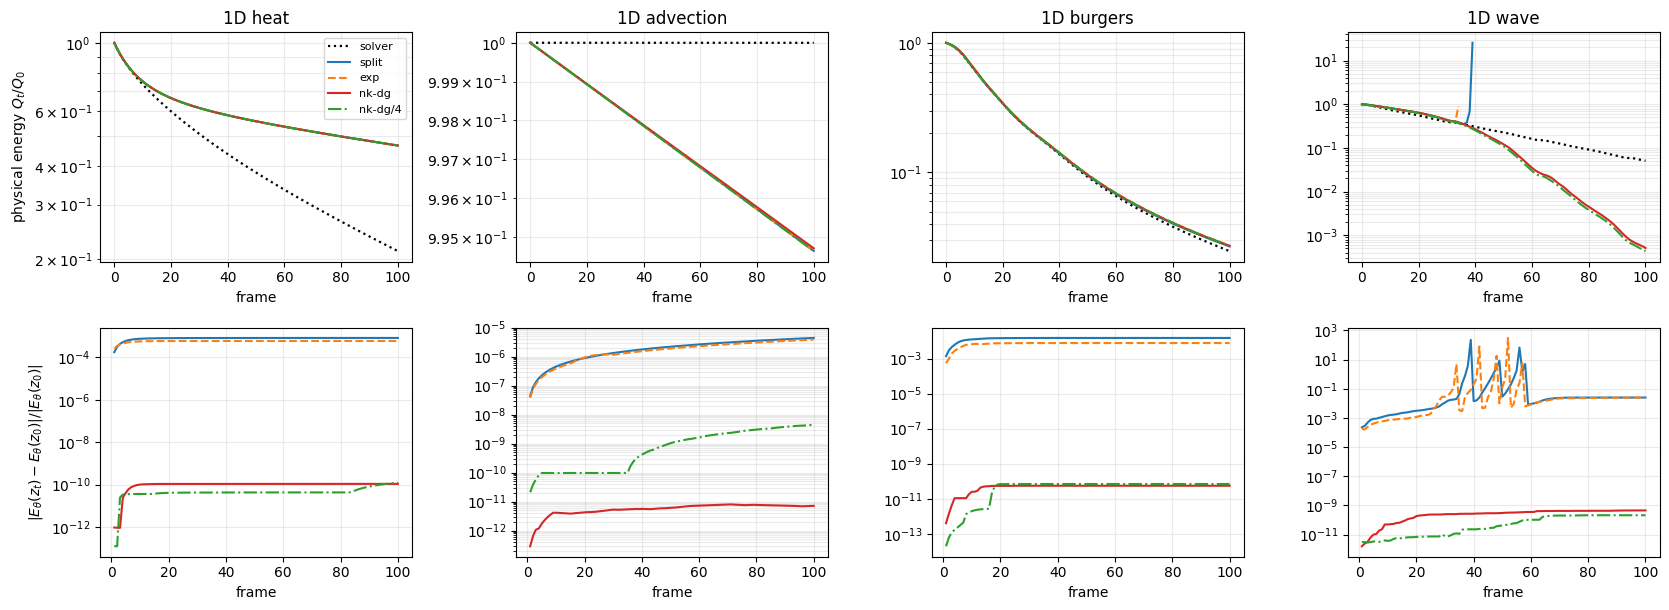

wrote /content/drive/MyDrive/pg_integrators/fig_integrators.pdf | /content/drive/MyDrive/pg_integrators/integrator_table_rows.tex | /content/drive/MyDrive/pg_integrators/integrator_study.csv


In [ ]:
# ===== Results: table, LaTeX rows, figure =====
df = pd.read_csv(RES); df = df[df.seed.isin(SEEDS) & df.pde.isin(PDES)]
ORDER = ['split', 'exp'] + ['nk-dg' if s == 1 else f'nk-dg/{s}' for s in NK_SUBS]
LAB = {'split': 'Split (paper)', 'exp': 'Exponential', 'nk-dg': 'DG, Newton--Krylov', **{f'nk-dg/{s}': f'DG, Newton--Krylov, {s} steps/frame' for s in NK_SUBS if s > 1}}
df['integrator'] = pd.Categorical(df['integrator'], ORDER, ordered=True); df['pde'] = pd.Categorical(df['pde'], PDES, ordered=True)
df['inputs'] = pd.Categorical(df['inputs'], INPUT_SETS, ordered=True); df = df.sort_values(['pde', 'inputs', 'seed', 'integrator'])
cols = ['fail', 'alive', 'unsolved', 'l2_10', 'l2_last', 'QQstar_last', 'maxQ', 'n_up', 'dE_max', 'dS_min', 's_max', 'newton_per_frame', 'krylov_per_frame', 'min_dt', 's_per_frame']
with pd.option_context('display.float_format', lambda x: f'{x:.3g}', 'display.width', 260, 'display.max_rows', 500):
    display(df.set_index(['pde', 'inputs', 'seed', 'integrator'])[[c_ for c_ in cols if c_ in df.columns]])

# ---- what to read off -----------------------------------------------------------------------------------------------------------
n_frames = T_LONG
def reached(g): return int((g['fail'].astype(str) == f'>{n_frames}').sum())
def intact(g): return int((g['alive'].map(lambda a: a.split('/')[0] == a.split('/')[1])).sum())
print('\nPer integrator, over all (equation, input set, seed) rollouts:')
for lab, g in df.groupby('integrator', observed=True):
    cost = g['s_per_frame'].mean() / df[df.integrator == 'split']['s_per_frame'].mean()
    print(f'  {lab:8s}: no sample lost in {intact(g):2d}/{len(g)} rollouts; error stays below 1 to frame {n_frames} in {reached(g):2d}/{len(g)}; '
          f'frames with rising energy {int(g["n_up"].sum()):3d}; first law: max |dE|/|E| per frame {g["dE_max"].max():.1e}; second law: min dS {g["dS_min"].min():.1e}; cost x{cost:.1f}')

# ---- LaTeX rows (appendix table: one row per equation and integrator; in distribution | amplitude x2) -------------------------------
def sci(x):
    if not np.isfinite(x): return '--'
    e = int(np.floor(np.log10(abs(x)))) if x != 0 else 0; return f'{x / 10 ** e:.1f}\\cdot10^{{{e}}}'
def cell(g, col, fmt='{:.3g}'):
    v = g[col]; return '--' if v.isna().all() else (fmt.format(v.mean()) if len(v) > 1 else fmt.format(v.iloc[0]))
tex = []
for pde in PDES:
    for k, lab in enumerate(ORDER):
        parts = []
        for name in ['in-distribution', 'amplitude x2']:
            g = df[(df.pde == pde) & (df.integrator == lab) & (df.inputs == name)]
            if len(g) == 0: parts.append(' & '.join(['--'] * 5)); continue
            fails = '/'.join(str(f).replace('>', '{>}') for f in g['fail']); lost = sum(int(a.split('/')[1]) - int(a.split('/')[0]) for a in g['alive']); tot = sum(int(a.split('/')[1]) for a in g['alive'])
            parts.append(f"${fails}$ & ${lost}/{tot}$ & ${cell(g, 'l2_10')}$ & ${sci(g['dE_max'].max())}$ & ${int(g['n_up'].sum())}$")
        cost = df[(df.pde == pde) & (df.integrator == lab)]['s_per_frame'].mean() / df[(df.pde == pde) & (df.integrator == 'split')]['s_per_frame'].mean()
        tex.append((f'\\multirow{{{len(ORDER)}}}{{*}}{{{pde.capitalize() if pde == "burgers" else pde}}}' if k == 0 else '') + f' & {LAB[lab]} & ' + ' & '.join(parts) + f' & ${cost:.1f}\\times$ \\\\')
    tex.append('\\midrule')
hdr = ('% columns: equation | integrator | in distribution: fail, samples lost, eps_10, max |dE|/|E| per frame, frames with rising Q |'
       ' amplitude x2: the same five | cost per frame relative to the split step\n')
open(f'{WORK}/integrator_table_rows.tex', 'w').write(hdr + '\n'.join(tex[:-1]) + '\n'); print('\n' + hdr + '\n'.join(tex[:-1]))

# ---- figure: physical energy and drift of the model's own energy along the rollouts (in distribution, first seed) -------------------
series = json.load(open(SER)); name = INPUT_SETS[0]; sd = SEEDS[0]
STY = {'solver': dict(c='k', ls=':', lw=1.6), 'split': dict(c='C0'), 'exp': dict(c='C1', ls='--'), 'nk-dg': dict(c='C3'), **{f'nk-dg/{s}': dict(c='C2', ls='-.') for s in NK_SUBS if s > 1}}
fig, ax = plt.subplots(2, len(PDES), figsize=(4.2 * len(PDES), 6.2), squeeze=False)
for j, pde in enumerate(PDES):
    for lab in ['solver'] + ORDER:
        s_ = series.get(f'{pde}|{sd}|{name}|{lab}')
        if s_ is None: continue
        q = np.array(s_['Q'], dtype=float); ax[0, j].semilogy(np.arange(len(q)), q, label=lab, **STY[lab])
        if 'E_drift' in s_:
            e = np.array(s_['E_drift'], dtype=float); ax[1, j].semilogy(np.arange(1, len(e)), np.maximum(e[1:], 1e-17), label=lab, **STY[lab])
    ax[0, j].set(title=f'1D {pde}', xlabel='frame'); ax[1, j].set(xlabel='frame'); ax[0, j].grid(alpha=0.25, which='both'); ax[1, j].grid(alpha=0.25, which='both')
ax[0, 0].set_ylabel(r'physical energy $Q_t/Q_0$'); ax[1, 0].set_ylabel(r'$|E_\theta(z_t)-E_\theta(z_0)|/|E_\theta(z_0)|$'); ax[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{WORK}/fig_integrators.pdf', bbox_inches='tight'); plt.show()
print('wrote', f'{WORK}/fig_integrators.pdf', '|', f'{WORK}/integrator_table_rows.tex', '|', RES)

## What to take to the paper
* **The solver question (Reviewer VbeA, Q3).** Check 1: residual and $|\Delta E_\theta|$ after the fixed point against the Newton–Krylov solve. Check 2: `dE_max` and `dS_min` of the `nk-dg` rows against the `split` rows — the first law at the solve tolerance instead of the split step's drift, and $\Delta S\ge0$ on every frame.
* **Divergence.** Compare `alive` and `n_up` between `split` and the `nk-dg` rows on the amplitude-×2 inputs. Where a Newton–Krylov row shows `unsolved` > 0, look at `s_max`: the solve stops when the latent entropy density has grown far outside its training range, which is a statement about the learned friction off distribution, not about the step.
* **What the solver does not change.** Rows where every integrator agrees (heat at frame 100, the wave on band-12 inputs) are the model's error, not the integrator's.
* **Accuracy and cost.** One discrete-gradient step per frame carries the phase error of the midpoint rule on the transport terms (compare `l2_10` of `nk-dg` and `split` on advection and the wave); four steps per frame remove it. `s_per_frame` gives the cost of each.
* **Exponential step.** The `exp` rows say whether replacing the sub-cycling buys stability; it carries no discrete energy law.

Files written to the work folder: `integrator_study.csv`, `solver_check.csv`, `integrator_table_rows.tex`, `fig_integrators.pdf`.